# Unidad 3 — Estructuración de datos y análisis exploratorio con Pandas
## Países, territorios y población: comparación de Colombia y Argentina

**Estudiante:** Completar antes de entregar  
**Asignatura, grupo y fecha:** Completar antes de entregar

### Objetivo
Aplicar el proceso de cargar, preparar, manipular y analizar datos con Pandas, siguiendo
el material **Data structuring** y los requisitos de la actividad de la Unidad 3.

### Preguntas
1. ¿Qué estructura, tipos de variables, faltantes y duplicados tienen los datos?
2. ¿Cómo se distribuyen los países y territorios por continente y densidad poblacional?
3. ¿Qué relación descriptiva existe entre superficie y población?
4. ¿Cómo evolucionó la población de Colombia y Argentina entre 1952 y 2007?

Las páginas 18–20 del PDF presentan los dos CSV que se emplean aquí. El notebook amplía
su ejemplo con limpieza explícita, visualizaciones e interpretaciones. No se utilizan cifras actuales
ni se confunde asociación con causalidad.

## 1. Relación con el temario

Una base de datos organiza información persistente; un **DataFrame** es una estructura tabular
en memoria y no reemplaza por sí solo un gestor de bases de datos. Un CSV es un archivo plano,
sin las restricciones ni los mecanismos de un sistema relacional.

El PDF distingue bases orientadas a objetos, distribuidas, almacenes de datos, NoSQL y relacionales.
En esta actividad basta con archivos tabulares: no se necesita instalar un servidor de bases de datos.
El **modelo de datos** debe dejar clara la unidad de observación y sus claves:

| Tabla | Unidad de observación | Clave comprobada | Variables principales |
| --- | --- | --- | --- |
| Geografía | País o territorio | `alpha_3` | Continente, superficie, población y códigos |
| Serie histórica | País en un año | `country`, `year` | País, año y población |

Las fuentes son **secundarias**, porque fueron recopiladas por terceros.
Las categorías como continente son cualitativas nominales; población es cuantitativa discreta;
superficie y densidad son cuantitativas continuas. El año es un indicador temporal expresado en enteros.
Un identificador numérico, como `geoname_id`, no es una medición y no debe interpretarse mediante correlaciones.

Los datos accesibles públicamente permiten reutilización y análisis, pero hay que comprobar su
procedencia, fecha, licencia y cobertura antes de usarlos para decisiones. Aquí se conservan las
fuentes y copias exactas; no se presupone que un enlace público garantice actualización o calidad.

## 2. Fuentes y reproducibilidad

**Datos geográficos**, referencia de la página 18:
https://raw.githubusercontent.com/lorey/list-of-countries/master/csv/countries.csv

**Serie de población**, referencia de las páginas 19–20:
https://raw.githubusercontent.com/DrueStaples/Population_Growth/master/countries.csv

**Ejemplo citado por el PDF:** Bagnato (2019), *Ejemplo de EDA*:
https://github.com/jbagnato/machine-learning/blob/master/Ejercicio_EDA.ipynb

La tabla geográfica no incluye un año de referencia por fila. La segunda cubre **1952–2007**,
con observaciones cada cinco años. Sus poblaciones no se mezclan como si correspondieran a la
misma fecha. El nombre de país tampoco debe usarse para unir fuentes sin revisar equivalencias.

El notebook incluye el texto de ambos CSV para poder ejecutarse sin descargar archivos.
Las celdas de datos pueden mantenerse plegadas al leer el informe. No se inventaron observaciones,
duplicados ni valores faltantes. Las huellas SHA-256 de las copias son:

- Geografía: `218fba77b7262952191e0edddc518b5dd94fed14282338f67ad08ad3c85cda07`.
- Población: `2a07bc64d768d12ba2f72fdc8f7a382fd312ef4a38e80bc183c47678469179e8`.

**Ejecución:** abrir este archivo en Google Colab o Jupyter y ejecutar todas las celdas en orden.
Se necesitan Python 3, Pandas, NumPy, Matplotlib y SciPy. Si faltan bibliotecas, ejecutar en una
celda `%pip install pandas numpy matplotlib scipy` y reiniciar el kernel. Solo esa instalación
inicial puede necesitar Internet. Las salidas y gráficas ya se guardan en este `.ipynb`.

In [1]:
import sys
from io import StringIO

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.stats import chi2_contingency
from IPython.display import display

pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print(f'Python {sys.version.split()[0]} | Pandas {pd.__version__} | NumPy {np.__version__}')
print(f'Matplotlib {matplotlib.__version__} | SciPy {scipy.__version__}')

# Una Series es un vector etiquetado; cada columna de un DataFrame es una Series.
ejemplo_serie = pd.Series(['Colombia', 'Argentina'], name='pais', dtype='string')
display(ejemplo_serie)

Python 3.12.14 | Pandas 2.2.3 | NumPy 2.3.5
Matplotlib 3.10.8 | SciPy 1.17.0


0     Colombia
1    Argentina
Name: pais, dtype: string

### Copias de los archivos CSV
Estas dos celdas guardan los datos de las fuentes anteriores como texto. `StringIO` permite
que `pd.read_csv` los lea como un archivo, conservando un único notebook como entrega.
La geografía usa `;` como separador y la población usa `,`.

In [2]:
CSV_GEOGRAFIA = "alpha_2;alpha_3;area;capital;continent;currency_code;currency_name;eqivalent_fips_code;fips;geoname_id;languages;name;neighbours;numeric;phone;population;postal_code_format;postal_code_regex;tld\nAD;AND;468;Andorra la Vella;EU;EUR;Euro;;AN;3041565;ca;Andorra;ES,FR;020;376;84000;AD###;^(?:AD)*(\\d{3})$;.ad\nAE;ARE;82880;Abu Dhabi;AS;AED;Dirham;;AE;290557;ar-AE,fa,en,hi,ur;United Arab Emirates;SA,OM;784;971;4975593;;;.ae\nAF;AFG;647500;Kabul;AS;AFN;Afghani;;AF;1149361;fa-AF,ps,uz-AF,tk;Afghanistan;TM,CN,IR,TJ,PK,UZ;004;93;29121286;;;.af\nAG;ATG;443;St. John's;NA;XCD;Dollar;;AC;3576396;en-AG;Antigua and Barbuda;;028;+1-268;86754;;;.ag\nAI;AIA;102;The Valley;NA;XCD;Dollar;;AV;3573511;en-AI;Anguilla;;660;+1-264;13254;;;.ai\nAL;ALB;28748;Tirana;EU;ALL;Lek;;AL;783754;sq,el;Albania;MK,GR,ME,RS,XK;008;355;2986952;;;.al\nAM;ARM;29800;Yerevan;AS;AMD;Dram;;AM;174982;hy;Armenia;GE,IR,AZ,TR;051;374;2968000;######;^(\\d{6})$;.am\nAO;AGO;1246700;Luanda;AF;AOA;Kwanza;;AO;3351879;pt-AO;Angola;CD,NA,ZM,CG;024;244;13068161;;;.ao\nAQ;ATA;14000000;;AN;;;;AY;6697173;;Antarctica;;010;;0;;;.aq\nAR;ARG;2766890;Buenos Aires;SA;ARS;Peso;;AR;3865483;es-AR,en,it,de,fr,gn;Argentina;CL,BO,UY,PY,BR;032;54;41343201;@####@@@;^[A-Z]?\\d{4}[A-Z]{0,3}$;.ar\nAS;ASM;199;Pago Pago;OC;USD;Dollar;;AQ;5880801;en-AS,sm,to;American Samoa;;016;+1-684;57881;;;.as\nAT;AUT;83858;Vienna;EU;EUR;Euro;;AU;2782113;de-AT,hr,hu,sl;Austria;CH,DE,HU,SK,CZ,IT,SI,LI;040;43;8205000;####;^(\\d{4})$;.at\nAU;AUS;7686850;Canberra;OC;AUD;Dollar;;AS;2077456;en-AU;Australia;;036;61;21515754;####;^(\\d{4})$;.au\nAW;ABW;193;Oranjestad;NA;AWG;Guilder;;AA;3577279;nl-AW,es,en;Aruba;;533;297;71566;;;.aw\nAX;ALA;1580;Mariehamn;EU;EUR;Euro;FI;;661882;sv-AX;Aland Islands;;248;+358-18;26711;#####;^(?:FI)*(\\d{5})$;.ax\nAZ;AZE;86600;Baku;AS;AZN;Manat;;AJ;587116;az,ru,hy;Azerbaijan;GE,IR,AM,TR,RU;031;994;8303512;AZ ####;^(?:AZ)*(\\d{4})$;.az\nBA;BIH;51129;Sarajevo;EU;BAM;Marka;;BK;3277605;bs,hr-BA,sr-BA;Bosnia and Herzegovina;HR,ME,RS;070;387;4590000;#####;^(\\d{5})$;.ba\nBB;BRB;431;Bridgetown;NA;BBD;Dollar;;BB;3374084;en-BB;Barbados;;052;+1-246;285653;BB#####;^(?:BB)*(\\d{5})$;.bb\nBD;BGD;144000;Dhaka;AS;BDT;Taka;;BG;1210997;bn-BD,en;Bangladesh;MM,IN;050;880;156118464;####;^(\\d{4})$;.bd\nBE;BEL;30510;Brussels;EU;EUR;Euro;;BE;2802361;nl-BE,fr-BE,de-BE;Belgium;DE,NL,LU,FR;056;32;10403000;####;^(\\d{4})$;.be\nBF;BFA;274200;Ouagadougou;AF;XOF;Franc;;UV;2361809;fr-BF;Burkina Faso;NE,BJ,GH,CI,TG,ML;854;226;16241811;;;.bf\nBG;BGR;110910;Sofia;EU;BGN;Lev;;BU;732800;bg,tr-BG,rom;Bulgaria;MK,GR,RO,TR,RS;100;359;7148785;####;^(\\d{4})$;.bg\nBH;BHR;665;Manama;AS;BHD;Dinar;;BA;290291;ar-BH,en,fa,ur;Bahrain;;048;973;738004;####|###;^(\\d{3}\\d?)$;.bh\nBI;BDI;27830;Bujumbura;AF;BIF;Franc;;BY;433561;fr-BI,rn;Burundi;TZ,CD,RW;108;257;9863117;;;.bi\nBJ;BEN;112620;Porto-Novo;AF;XOF;Franc;;BN;2395170;fr-BJ;Benin;NE,TG,BF,NG;204;229;9056010;;;.bj\nBL;BLM;21;Gustavia;NA;EUR;Euro;;TB;3578476;fr;Saint Barthelemy;;652;590;8450;### ###;;.gp\nBM;BMU;53;Hamilton;NA;BMD;Dollar;;BD;3573345;en-BM,pt;Bermuda;;060;+1-441;65365;@@ ##;^([A-Z]{2}\\d{2})$;.bm\nBN;BRN;5770;Bandar Seri Begawan;AS;BND;Dollar;;BX;1820814;ms-BN,en-BN;Brunei;MY;096;673;395027;@@####;^([A-Z]{2}\\d{4})$;.bn\nBO;BOL;1098580;Sucre;SA;BOB;Boliviano;;BL;3923057;es-BO,qu,ay;Bolivia;PE,CL,PY,BR,AR;068;591;9947418;;;.bo\nBQ;BES;328;;NA;USD;Dollar;;;7626844;nl,pap,en;Bonaire, Saint Eustatius and Saba ;;535;599;18012;;;.bq\nBR;BRA;8511965;Brasilia;SA;BRL;Real;;BR;3469034;pt-BR,es,en,fr;Brazil;SR,PE,BO,UY,GY,PY,GF,VE,CO,AR;076;55;201103330;#####-###;^\\d{5}-\\d{3}$;.br\nBS;BHS;13940;Nassau;NA;BSD;Dollar;;BF;3572887;en-BS;Bahamas;;044;+1-242;301790;;;.bs\nBT;BTN;47000;Thimphu;AS;BTN;Ngultrum;;BT;1252634;dz;Bhutan;CN,IN;064;975;699847;;;.bt\nBV;BVT;49;;AN;NOK;Krone;;BV;3371123;;Bouvet Island;;074;;0;;;.bv\nBW;BWA;600370;Gaborone;AF;BWP;Pula;;BC;933860;en-BW,tn-BW;Botswana;ZW,ZA,NA;072;267;2029307;;;.bw\nBY;BLR;207600;Minsk;EU;BYR;Ruble;;BO;630336;be,ru;Belarus;PL,LT,UA,RU,LV;112;375;9685000;######;^(\\d{6})$;.by\nBZ;BLZ;22966;Belmopan;NA;BZD;Dollar;;BH;3582678;en-BZ,es;Belize;GT,MX;084;501;314522;;;.bz\nCA;CAN;9984670;Ottawa;NA;CAD;Dollar;;CA;6251999;en-CA,fr-CA,iu;Canada;US;124;1;33679000;@#@ #@#;^([ABCEGHJKLMNPRSTVXY]\\d[ABCEGHJKLMNPRSTVWXYZ]) ?(\\d[ABCEGHJKLMNPRSTVWXYZ]\\d)$ ;.ca\nCC;CCK;14;West Island;AS;AUD;Dollar;;CK;1547376;ms-CC,en;Cocos Islands;;166;61;628;;;.cc\nCD;COD;2345410;Kinshasa;AF;CDF;Franc;;CG;203312;fr-CD,ln,kg;Democratic Republic of the Congo;TZ,CF,SS,RW,ZM,BI,UG,CG,AO;180;243;70916439;;;.cd\nCF;CAF;622984;Bangui;AF;XAF;Franc;;CT;239880;fr-CF,sg,ln,kg;Central African Republic;TD,SD,CD,SS,CM,CG;140;236;4844927;;;.cf\nCG;COG;342000;Brazzaville;AF;XAF;Franc;;CF;2260494;fr-CG,kg,ln-CG;Republic of the Congo;CF,GA,CD,CM,AO;178;242;3039126;;;.cg\nCH;CHE;41290;Bern;EU;CHF;Franc;;SZ;2658434;de-CH,fr-CH,it-CH,rm;Switzerland;DE,IT,LI,FR,AT;756;41;7581000;####;^(\\d{4})$;.ch\nCI;CIV;322460;Yamoussoukro;AF;XOF;Franc;;IV;2287781;fr-CI;Ivory Coast;LR,GH,GN,BF,ML;384;225;21058798;;;.ci\nCK;COK;240;Avarua;OC;NZD;Dollar;;CW;1899402;en-CK,mi;Cook Islands;;184;682;21388;;;.ck\nCL;CHL;756950;Santiago;SA;CLP;Peso;;CI;3895114;es-CL;Chile;PE,BO,AR;152;56;16746491;#######;^(\\d{7})$;.cl\nCM;CMR;475440;Yaounde;AF;XAF;Franc;;CM;2233387;en-CM,fr-CM;Cameroon;TD,CF,GA,GQ,CG,NG;120;237;19294149;;;.cm\nCN;CHN;9596960;Beijing;AS;CNY;Yuan Renminbi;;CH;1814991;zh-CN,yue,wuu,dta,ug,za;China;LA,BT,TJ,KZ,MN,AF,NP,MM,KG,PK,KP,RU,VN,IN;156;86;1330044000;######;^(\\d{6})$;.cn\nCO;COL;1138910;Bogota;SA;COP;Peso;;CO;3686110;es-CO;Colombia;EC,PE,PA,BR,VE;170;57;47790000;;;.co\nCR;CRI;51100;San Jose;NA;CRC;Colon;;CS;3624060;es-CR,en;Costa Rica;PA,NI;188;506;4516220;####;^(\\d{4})$;.cr\nCU;CUB;110860;Havana;NA;CUP;Peso;;CU;3562981;es-CU;Cuba;US;192;53;11423000;CP #####;^(?:CP)*(\\d{5})$;.cu\nCV;CPV;4033;Praia;AF;CVE;Escudo;;CV;3374766;pt-CV;Cape Verde;;132;238;508659;####;^(\\d{4})$;.cv\nCW;CUW;444; Willemstad;NA;ANG;Guilder;;UC;7626836;nl,pap;Curacao;;531;599;141766;;;.cw\nCX;CXR;135;Flying Fish Cove;AS;AUD;Dollar;;KT;2078138;en,zh,ms-CC;Christmas Island;;162;61;1500;####;^(\\d{4})$;.cx\nCY;CYP;9250;Nicosia;EU;EUR;Euro;;CY;146669;el-CY,tr-CY,en;Cyprus;;196;357;1102677;####;^(\\d{4})$;.cy\nCZ;CZE;78866;Prague;EU;CZK;Koruna;;EZ;3077311;cs,sk;Czechia;PL,DE,SK,AT;203;420;10476000;### ##;^\\d{3}\\s?\\d{2}$;.cz\nDE;DEU;357021;Berlin;EU;EUR;Euro;;GM;2921044;de;Germany;CH,PL,NL,DK,BE,CZ,LU,FR,AT;276;49;81802257;#####;^(\\d{5})$;.de\nDJ;DJI;23000;Djibouti;AF;DJF;Franc;;DJ;223816;fr-DJ,ar,so-DJ,aa;Djibouti;ER,ET,SO;262;253;740528;;;.dj\nDK;DNK;43094;Copenhagen;EU;DKK;Krone;;DA;2623032;da-DK,en,fo,de-DK;Denmark;DE;208;45;5484000;####;^(\\d{4})$;.dk\nDM;DMA;754;Roseau;NA;XCD;Dollar;;DO;3575830;en-DM;Dominica;;212;+1-767;72813;;;.dm\nDO;DOM;48730;Santo Domingo;NA;DOP;Peso;;DR;3508796;es-DO;Dominican Republic;HT;214;+1-809 and 1-829;9823821;#####;^(\\d{5})$;.do\nDZ;DZA;2381740;Algiers;AF;DZD;Dinar;;AG;2589581;ar-DZ;Algeria;NE,EH,LY,MR,TN,MA,ML;012;213;34586184;#####;^(\\d{5})$;.dz\nEC;ECU;283560;Quito;SA;USD;Dollar;;EC;3658394;es-EC;Ecuador;PE,CO;218;593;14790608;@####@;^([a-zA-Z]\\d{4}[a-zA-Z])$;.ec\nEE;EST;45226;Tallinn;EU;EUR;Euro;;EN;453733;et,ru;Estonia;RU,LV;233;372;1291170;#####;^(\\d{5})$;.ee\nEG;EGY;1001450;Cairo;AF;EGP;Pound;;EG;357994;ar-EG,en,fr;Egypt;LY,SD,IL,PS;818;20;80471869;#####;^(\\d{5})$;.eg\nEH;ESH;266000;El-Aaiun;AF;MAD;Dirham;;WI;2461445;ar,mey;Western Sahara;DZ,MR,MA;732;212;273008;;;.eh\nER;ERI;121320;Asmara;AF;ERN;Nakfa;;ER;338010;aa-ER,ar,tig,kun,ti-ER;Eritrea;ET,SD,DJ;232;291;5792984;;;.er\nES;ESP;504782;Madrid;EU;EUR;Euro;;SP;2510769;es-ES,ca,gl,eu,oc;Spain;AD,PT,GI,FR,MA;724;34;46505963;#####;^(\\d{5})$;.es\nET;ETH;1127127;Addis Ababa;AF;ETB;Birr;;ET;337996;am,en-ET,om-ET,ti-ET,so-ET,sid;Ethiopia;ER,KE,SD,SS,SO,DJ;231;251;88013491;####;^(\\d{4})$;.et\nFI;FIN;337030;Helsinki;EU;EUR;Euro;;FI;660013;fi-FI,sv-FI,smn;Finland;NO,RU,SE;246;358;5244000;#####;^(?:FI)*(\\d{5})$;.fi\nFJ;FJI;18270;Suva;OC;FJD;Dollar;;FJ;2205218;en-FJ,fj;Fiji;;242;679;875983;;;.fj\nFK;FLK;12173;Stanley;SA;FKP;Pound;;FK;3474414;en-FK;Falkland Islands;;238;500;2638;;;.fk\nFM;FSM;702;Palikir;OC;USD;Dollar;;FM;2081918;en-FM,chk,pon,yap,kos,uli,woe,nkr,kpg;Micronesia;;583;691;107708;#####;^(\\d{5})$;.fm\nFO;FRO;1399;Torshavn;EU;DKK;Krone;;FO;2622320;fo,da-FO;Faroe Islands;;234;298;48228;FO-###;^(?:FO)*(\\d{3})$;.fo\nFR;FRA;547030;Paris;EU;EUR;Euro;;FR;3017382;fr-FR,frp,br,co,ca,eu,oc;France;CH,DE,BE,LU,IT,AD,MC,ES;250;33;64768389;#####;^(\\d{5})$;.fr\nGA;GAB;267667;Libreville;AF;XAF;Franc;;GB;2400553;fr-GA;Gabon;CM,GQ,CG;266;241;1545255;;;.ga\nGB;GBR;244820;London;EU;GBP;Pound;;UK;2635167;en-GB,cy-GB,gd;United Kingdom;IE;826;44;62348447;@# #@@|@## #@@|@@# #@@|@@## #@@|@#@ #@@|@@#@ #@@|GIR0AA;^((?:(?:[A-PR-UWYZ][A-HK-Y]\\d[ABEHMNPRV-Y0-9]|[A-PR-UWYZ]\\d[A-HJKPS-UW0-9])\\s\\d[ABD-HJLNP-UW-Z]{2})|GIR\\s?0AA)$;.uk\nGD;GRD;344;St. George's;NA;XCD;Dollar;;GJ;3580239;en-GD;Grenada;;308;+1-473;107818;;;.gd\nGE;GEO;69700;Tbilisi;AS;GEL;Lari;;GG;614540;ka,ru,hy,az;Georgia;AM,AZ,TR,RU;268;995;4630000;####;^(\\d{4})$;.ge\nGF;GUF;91000;Cayenne;SA;EUR;Euro;;FG;3381670;fr-GF;French Guiana;SR,BR;254;594;195506;#####;^((97|98)3\\d{2})$;.gf\nGG;GGY;78;St Peter Port;EU;GBP;Pound;;GK;3042362;en,fr;Guernsey;;831;+44-1481;65228;@# #@@|@## #@@|@@# #@@|@@## #@@|@#@ #@@|@@#@ #@@|GIR0AA;^((?:(?:[A-PR-UWYZ][A-HK-Y]\\d[ABEHMNPRV-Y0-9]|[A-PR-UWYZ]\\d[A-HJKPS-UW0-9])\\s\\d[ABD-HJLNP-UW-Z]{2})|GIR\\s?0AA)$;.gg\nGH;GHA;239460;Accra;AF;GHS;Cedi;;GH;2300660;en-GH,ak,ee,tw;Ghana;CI,TG,BF;288;233;24339838;;;.gh\nGI;GIB;6.5;Gibraltar;EU;GIP;Pound;;GI;2411586;en-GI,es,it,pt;Gibraltar;ES;292;350;27884;;;.gi\nGL;GRL;2166086;Nuuk;NA;DKK;Krone;;GL;3425505;kl,da-GL,en;Greenland;;304;299;56375;####;^(\\d{4})$;.gl\nGM;GMB;11300;Banjul;AF;GMD;Dalasi;;GA;2413451;en-GM,mnk,wof,wo,ff;Gambia;SN;270;220;1593256;;;.gm\nGN;GIN;245857;Conakry;AF;GNF;Franc;;GV;2420477;fr-GN;Guinea;LR,SN,SL,CI,GW,ML;324;224;10324025;;;.gn\nGP;GLP;1780;Basse-Terre;NA;EUR;Euro;;GP;3579143;fr-GP;Guadeloupe;;312;590;443000;#####;^((97|98)\\d{3})$;.gp\nGQ;GNQ;28051;Malabo;AF;XAF;Franc;;EK;2309096;es-GQ,fr;Equatorial Guinea;GA,CM;226;240;1014999;;;.gq\nGR;GRC;131940;Athens;EU;EUR;Euro;;GR;390903;el-GR,en,fr;Greece;AL,MK,TR,BG;300;30;11000000;### ##;^(\\d{5})$;.gr\nGS;SGS;3903;Grytviken;AN;GBP;Pound;;SX;3474415;en;South Georgia and the South Sandwich Islands;;239;;30;;;.gs\nGT;GTM;108890;Guatemala City;NA;GTQ;Quetzal;;GT;3595528;es-GT;Guatemala;MX,HN,BZ,SV;320;502;13550440;#####;^(\\d{5})$;.gt\nGU;GUM;549;Hagatna;OC;USD;Dollar;;GQ;4043988;en-GU,ch-GU;Guam;;316;+1-671;159358;969##;^(969\\d{2})$;.gu\nGW;GNB;36120;Bissau;AF;XOF;Franc;;PU;2372248;pt-GW,pov;Guinea-Bissau;SN,GN;624;245;1565126;####;^(\\d{4})$;.gw\nGY;GUY;214970;Georgetown;SA;GYD;Dollar;;GY;3378535;en-GY;Guyana;SR,BR,VE;328;592;748486;;;.gy\nHK;HKG;1092;Hong Kong;AS;HKD;Dollar;;HK;1819730;zh-HK,yue,zh,en;Hong Kong;;344;852;6898686;;;.hk\nHM;HMD;412;;AN;AUD;Dollar;;HM;1547314;;Heard Island and McDonald Islands;;334; ;0;;;.hm\nHN;HND;112090;Tegucigalpa;NA;HNL;Lempira;;HO;3608932;es-HN;Honduras;GT,NI,SV;340;504;7989415;@@####;^([A-Z]{2}\\d{4})$;.hn\nHR;HRV;56542;Zagreb;EU;HRK;Kuna;;HR;3202326;hr-HR,sr;Croatia;HU,SI,BA,ME,RS;191;385;4284889;#####;^(?:HR)*(\\d{5})$;.hr\nHT;HTI;27750;Port-au-Prince;NA;HTG;Gourde;;HA;3723988;ht,fr-HT;Haiti;DO;332;509;9648924;HT####;^(?:HT)*(\\d{4})$;.ht\nHU;HUN;93030;Budapest;EU;HUF;Forint;;HU;719819;hu-HU;Hungary;SK,SI,RO,UA,HR,AT,RS;348;36;9982000;####;^(\\d{4})$;.hu\nID;IDN;1919440;Jakarta;AS;IDR;Rupiah;;ID;1643084;id,en,nl,jv;Indonesia;PG,TL,MY;360;62;242968342;#####;^(\\d{5})$;.id\nIE;IRL;70280;Dublin;EU;EUR;Euro;;EI;2963597;en-IE,ga-IE;Ireland;GB;372;353;4622917;@@@ @@@@;^[A-Z]\\d{2}$|^[A-Z]{3}[A-Z]{4}$;.ie\nIL;ISR;20770;Jerusalem;AS;ILS;Shekel;;IS;294640;he,ar-IL,en-IL,;Israel;SY,JO,LB,EG,PS;376;972;7353985;#####;^(\\d{5})$;.il\nIM;IMN;572;Douglas;EU;GBP;Pound;;IM;3042225;en,gv;Isle of Man;;833;+44-1624;75049;@# #@@|@## #@@|@@# #@@|@@## #@@|@#@ #@@|@@#@ #@@|GIR0AA;^((?:(?:[A-PR-UWYZ][A-HK-Y]\\d[ABEHMNPRV-Y0-9]|[A-PR-UWYZ]\\d[A-HJKPS-UW0-9])\\s\\d[ABD-HJLNP-UW-Z]{2})|GIR\\s?0AA)$;.im\nIN;IND;3287590;New Delhi;AS;INR;Rupee;;IN;1269750;en-IN,hi,bn,te,mr,ta,ur,gu,kn,ml,or,pa,as,bh,sat,ks,ne,sd,kok,doi,mni,sit,sa,fr,lus,inc;India;CN,NP,MM,BT,PK,BD;356;91;1173108018;######;^(\\d{6})$;.in\nIO;IOT;60;Diego Garcia;AS;USD;Dollar;;IO;1282588;en-IO;British Indian Ocean Territory;;086;246;4000;;;.io\nIQ;IRQ;437072;Baghdad;AS;IQD;Dinar;;IZ;99237;ar-IQ,ku,hy;Iraq;SY,SA,IR,JO,TR,KW;368;964;29671605;#####;^(\\d{5})$;.iq\nIR;IRN;1648000;Tehran;AS;IRR;Rial;;IR;130758;fa-IR,ku;Iran;TM,AF,IQ,AM,PK,AZ,TR;364;98;76923300;##########;^(\\d{10})$;.ir\nIS;ISL;103000;Reykjavik;EU;ISK;Krona;;IC;2629691;is,en,de,da,sv,no;Iceland;;352;354;308910;###;^(\\d{3})$;.is\nIT;ITA;301230;Rome;EU;EUR;Euro;;IT;3175395;it-IT,de-IT,fr-IT,sc,ca,co,sl;Italy;CH,VA,SI,SM,FR,AT;380;39;60340328;#####;^(\\d{5})$;.it\nJE;JEY;116;Saint Helier;EU;GBP;Pound;;JE;3042142;en,pt;Jersey;;832;+44-1534;90812;@# #@@|@## #@@|@@# #@@|@@## #@@|@#@ #@@|@@#@ #@@|GIR0AA;^((?:(?:[A-PR-UWYZ][A-HK-Y]\\d[ABEHMNPRV-Y0-9]|[A-PR-UWYZ]\\d[A-HJKPS-UW0-9])\\s\\d[ABD-HJLNP-UW-Z]{2})|GIR\\s?0AA)$;.je\nJM;JAM;10991;Kingston;NA;JMD;Dollar;;JM;3489940;en-JM;Jamaica;;388;+1-876;2847232;;;.jm\nJO;JOR;92300;Amman;AS;JOD;Dinar;;JO;248816;ar-JO,en;Jordan;SY,SA,IQ,IL,PS;400;962;6407085;#####;^(\\d{5})$;.jo\nJP;JPN;377835;Tokyo;AS;JPY;Yen;;JA;1861060;ja;Japan;;392;81;127288000;###-####;^\\d{3}-\\d{4}$;.jp\nKE;KEN;582650;Nairobi;AF;KES;Shilling;;KE;192950;en-KE,sw-KE;Kenya;ET,TZ,SS,SO,UG;404;254;40046566;#####;^(\\d{5})$;.ke\nKG;KGZ;198500;Bishkek;AS;KGS;Som;;KG;1527747;ky,uz,ru;Kyrgyzstan;CN,TJ,UZ,KZ;417;996;5776500;######;^(\\d{6})$;.kg\nKH;KHM;181040;Phnom Penh;AS;KHR;Riels;;CB;1831722;km,fr,en;Cambodia;LA,TH,VN;116;855;14453680;#####;^(\\d{5})$;.kh\nKI;KIR;811;Tarawa;OC;AUD;Dollar;;KR;4030945;en-KI,gil;Kiribati;;296;686;92533;;;.ki\nKM;COM;2170;Moroni;AF;KMF;Franc;;CN;921929;ar,fr-KM;Comoros;;174;269;773407;;;.km\nKN;KNA;261;Basseterre;NA;XCD;Dollar;;SC;3575174;en-KN;Saint Kitts and Nevis;;659;+1-869;51134;;;.kn\nKP;PRK;120540;Pyongyang;AS;KPW;Won;;KN;1873107;ko-KP;North Korea;CN,KR,RU;408;850;22912177;###-###;^(\\d{6})$;.kp\nKR;KOR;98480;Seoul;AS;KRW;Won;;KS;1835841;ko-KR,en;South Korea;KP;410;82;48422644;SEOUL ###-###;^(?:SEOUL)*(\\d{6})$;.kr\nXK;XKX;10908;Pristina;EU;EUR;Euro;;KV;831053;sq,sr;Kosovo;RS,AL,MK,ME;0;;1800000;;;\nKW;KWT;17820;Kuwait City;AS;KWD;Dinar;;KU;285570;ar-KW,en;Kuwait;SA,IQ;414;965;2789132;#####;^(\\d{5})$;.kw\nKY;CYM;262;George Town;NA;KYD;Dollar;;CJ;3580718;en-KY;Cayman Islands;;136;+1-345;44270;;;.ky\nKZ;KAZ;2717300;Astana;AS;KZT;Tenge;;KZ;1522867;kk,ru;Kazakhstan;TM,CN,KG,UZ,RU;398;7;15340000;######;^(\\d{6})$;.kz\nLA;LAO;236800;Vientiane;AS;LAK;Kip;;LA;1655842;lo,fr,en;Laos;CN,MM,KH,TH,VN;418;856;6368162;#####;^(\\d{5})$;.la\nLB;LBN;10400;Beirut;AS;LBP;Pound;;LE;272103;ar-LB,fr-LB,en,hy;Lebanon;SY,IL;422;961;4125247;#### ####|####;^(\\d{4}(\\d{4})?)$;.lb\nLC;LCA;616;Castries;NA;XCD;Dollar;;ST;3576468;en-LC;Saint Lucia;;662;+1-758;160922;;;.lc\nLI;LIE;160;Vaduz;EU;CHF;Franc;;LS;3042058;de-LI;Liechtenstein;CH,AT;438;423;35000;####;^(\\d{4})$;.li\nLK;LKA;65610;Colombo;AS;LKR;Rupee;;CE;1227603;si,ta,en;Sri Lanka;;144;94;21513990;#####;^(\\d{5})$;.lk\nLR;LBR;111370;Monrovia;AF;LRD;Dollar;;LI;2275384;en-LR;Liberia;SL,CI,GN;430;231;3685076;####;^(\\d{4})$;.lr\nLS;LSO;30355;Maseru;AF;LSL;Loti;;LT;932692;en-LS,st,zu,xh;Lesotho;ZA;426;266;1919552;###;^(\\d{3})$;.ls\nLT;LTU;65200;Vilnius;EU;EUR;Euro;;LH;597427;lt,ru,pl;Lithuania;PL,BY,RU,LV;440;370;2944459;LT-#####;^(?:LT)*(\\d{5})$;.lt\nLU;LUX;2586;Luxembourg;EU;EUR;Euro;;LU;2960313;lb,de-LU,fr-LU;Luxembourg;DE,BE,FR;442;352;497538;L-####;^(?:L-)?\\d{4}$;.lu\nLV;LVA;64589;Riga;EU;EUR;Euro;;LG;458258;lv,ru,lt;Latvia;LT,EE,BY,RU;428;371;2217969;LV-####;^(?:LV)*(\\d{4})$;.lv\nLY;LBY;1759540;Tripoli;AF;LYD;Dinar;;LY;2215636;ar-LY,it,en;Libya;TD,NE,DZ,SD,TN,EG;434;218;6461454;;;.ly\nMA;MAR;446550;Rabat;AF;MAD;Dirham;;MO;2542007;ar-MA,fr;Morocco;DZ,EH,ES;504;212;31627428;#####;^(\\d{5})$;.ma\nMC;MCO;1.95;Monaco;EU;EUR;Euro;;MN;2993457;fr-MC,en,it;Monaco;FR;492;377;32965;#####;^(\\d{5})$;.mc\nMD;MDA;33843;Chisinau;EU;MDL;Leu;;MD;617790;ro,ru,gag,tr;Moldova;RO,UA;498;373;4324000;MD-####;^MD-\\d{4}$;.md\nME;MNE;14026;Podgorica;EU;EUR;Euro;;MJ;3194884;sr,hu,bs,sq,hr,rom;Montenegro;AL,HR,BA,RS,XK;499;382;666730;#####;^(\\d{5})$;.me\nMF;MAF;53;Marigot;NA;EUR;Euro;;RN;3578421;fr;Saint Martin;SX;663;590;35925;### ###;;.gp\nMG;MDG;587040;Antananarivo;AF;MGA;Ariary;;MA;1062947;fr-MG,mg;Madagascar;;450;261;21281844;###;^(\\d{3})$;.mg\nMH;MHL;181.3;Majuro;OC;USD;Dollar;;RM;2080185;mh,en-MH;Marshall Islands;;584;692;65859;;;.mh\nMK;MKD;25333;Skopje;EU;MKD;Denar;;MK;718075;mk,sq,tr,rmm,sr;Macedonia;AL,GR,BG,RS,XK;807;389;2062294;####;^(\\d{4})$;.mk\nML;MLI;1240000;Bamako;AF;XOF;Franc;;ML;2453866;fr-ML,bm;Mali;SN,NE,DZ,CI,GN,MR,BF;466;223;13796354;;;.ml\nMM;MMR;678500;Nay Pyi Taw;AS;MMK;Kyat;;BM;1327865;my;Myanmar;CN,LA,TH,BD,IN;104;95;53414374;#####;^(\\d{5})$;.mm\nMN;MNG;1565000;Ulan Bator;AS;MNT;Tugrik;;MG;2029969;mn,ru;Mongolia;CN,RU;496;976;3086918;######;^(\\d{6})$;.mn\nMO;MAC;254;Macao;AS;MOP;Pataca;;MC;1821275;zh,zh-MO,pt;Macao;;446;853;449198;;;.mo\nMP;MNP;477;Saipan;OC;USD;Dollar;;CQ;4041468;fil,tl,zh,ch-MP,en-MP;Northern Mariana Islands;;580;+1-670;53883;;;.mp\nMQ;MTQ;1100;Fort-de-France;NA;EUR;Euro;;MB;3570311;fr-MQ;Martinique;;474;596;432900;#####;^(\\d{5})$;.mq\nMR;MRT;1030700;Nouakchott;AF;MRO;Ouguiya;;MR;2378080;ar-MR,fuc,snk,fr,mey,wo;Mauritania;SN,DZ,EH,ML;478;222;3205060;;;.mr\nMS;MSR;102;Plymouth;NA;XCD;Dollar;;MH;3578097;en-MS;Montserrat;;500;+1-664;9341;;;.ms\nMT;MLT;316;Valletta;EU;EUR;Euro;;MT;2562770;mt,en-MT;Malta;;470;356;403000;@@@ ####;^[A-Z]{3}\\s?\\d{4}$;.mt\nMU;MUS;2040;Port Louis;AF;MUR;Rupee;;MP;934292;en-MU,bho,fr;Mauritius;;480;230;1294104;;;.mu\nMV;MDV;300;Male;AS;MVR;Rufiyaa;;MV;1282028;dv,en;Maldives;;462;960;395650;#####;^(\\d{5})$;.mv\nMW;MWI;118480;Lilongwe;AF;MWK;Kwacha;;MI;927384;ny,yao,tum,swk;Malawi;TZ,MZ,ZM;454;265;15447500;;;.mw\nMX;MEX;1972550;Mexico City;NA;MXN;Peso;;MX;3996063;es-MX;Mexico;GT,US,BZ;484;52;112468855;#####;^(\\d{5})$;.mx\nMY;MYS;329750;Kuala Lumpur;AS;MYR;Ringgit;;MY;1733045;ms-MY,en,zh,ta,te,ml,pa,th;Malaysia;BN,TH,ID;458;60;28274729;#####;^(\\d{5})$;.my\nMZ;MOZ;801590;Maputo;AF;MZN;Metical;;MZ;1036973;pt-MZ,vmw;Mozambique;ZW,TZ,SZ,ZA,ZM,MW;508;258;22061451;####;^(\\d{4})$;.mz\nNA;NAM;825418;Windhoek;AF;NAD;Dollar;;WA;3355338;en-NA,af,de,hz,naq;Namibia;ZA,BW,ZM,AO;516;264;2128471;;;.na\nNC;NCL;19060;Noumea;OC;XPF;Franc;;NC;2139685;fr-NC;New Caledonia;;540;687;216494;#####;^(\\d{5})$;.nc\nNE;NER;1267000;Niamey;AF;XOF;Franc;;NG;2440476;fr-NE,ha,kr,dje;Niger;TD,BJ,DZ,LY,BF,NG,ML;562;227;15878271;####;^(\\d{4})$;.ne\nNF;NFK;34.6;Kingston;OC;AUD;Dollar;;NF;2155115;en-NF;Norfolk Island;;574;672;1828;####;^(\\d{4})$;.nf\nNG;NGA;923768;Abuja;AF;NGN;Naira;;NI;2328926;en-NG,ha,yo,ig,ff;Nigeria;TD,NE,BJ,CM;566;234;154000000;######;^(\\d{6})$;.ng\nNI;NIC;129494;Managua;NA;NIO;Cordoba;;NU;3617476;es-NI,en;Nicaragua;CR,HN;558;505;5995928;###-###-#;^(\\d{7})$;.ni\nNL;NLD;41526;Amsterdam;EU;EUR;Euro;;NL;2750405;nl-NL,fy-NL;Netherlands;DE,BE;528;31;16645000;#### @@;^(\\d{4}[A-Z]{2})$;.nl\nNO;NOR;324220;Oslo;EU;NOK;Krone;;NO;3144096;no,nb,nn,se,fi;Norway;FI,RU,SE;578;47;5009150;####;^(\\d{4})$;.no\nNP;NPL;140800;Kathmandu;AS;NPR;Rupee;;NP;1282988;ne,en;Nepal;CN,IN;524;977;28951852;#####;^(\\d{5})$;.np\nNR;NRU;21;Yaren;OC;AUD;Dollar;;NR;2110425;na,en-NR;Nauru;;520;674;10065;;;.nr\nNU;NIU;260;Alofi;OC;NZD;Dollar;;NE;4036232;niu,en-NU;Niue;;570;683;2166;;;.nu\nNZ;NZL;268680;Wellington;OC;NZD;Dollar;;NZ;2186224;en-NZ,mi;New Zealand;;554;64;4252277;####;^(\\d{4})$;.nz\nOM;OMN;212460;Muscat;AS;OMR;Rial;;MU;286963;ar-OM,en,bal,ur;Oman;SA,YE,AE;512;968;2967717;###;^(\\d{3})$;.om\nPA;PAN;78200;Panama City;NA;PAB;Balboa;;PM;3703430;es-PA,en;Panama;CR,CO;591;507;3410676;;;.pa\nPE;PER;1285220;Lima;SA;PEN;Sol;;PE;3932488;es-PE,qu,ay;Peru;EC,CL,BO,BR,CO;604;51;29907003;;;.pe\nPF;PYF;4167;Papeete;OC;XPF;Franc;;FP;4030656;fr-PF,ty;French Polynesia;;258;689;270485;#####;^((97|98)7\\d{2})$;.pf\nPG;PNG;462840;Port Moresby;OC;PGK;Kina;;PP;2088628;en-PG,ho,meu,tpi;Papua New Guinea;ID;598;675;6064515;###;^(\\d{3})$;.pg\nPH;PHL;300000;Manila;AS;PHP;Peso;;RP;1694008;tl,en-PH,fil;Philippines;;608;63;99900177;####;^(\\d{4})$;.ph\nPK;PAK;803940;Islamabad;AS;PKR;Rupee;;PK;1168579;ur-PK,en-PK,pa,sd,ps,brh;Pakistan;CN,AF,IR,IN;586;92;184404791;#####;^(\\d{5})$;.pk\nPL;POL;312685;Warsaw;EU;PLN;Zloty;;PL;798544;pl;Poland;DE,LT,SK,CZ,BY,UA,RU;616;48;38500000;##-###;^\\d{2}-\\d{3}$;.pl\nPM;SPM;242;Saint-Pierre;NA;EUR;Euro;;SB;3424932;fr-PM;Saint Pierre and Miquelon;;666;508;7012;#####;^(97500)$;.pm\nPN;PCN;47;Adamstown;OC;NZD;Dollar;;PC;4030699;en-PN;Pitcairn;;612;870;46;;;.pn\nPR;PRI;9104;San Juan;NA;USD;Dollar;;RQ;4566966;en-PR,es-PR;Puerto Rico;;630;+1-787 and 1-939;3916632;#####-####;^00[679]\\d{2}(?:-\\d{4})?$;.pr\nPS;PSE;5970;East Jerusalem;AS;ILS;Shekel;;WE;6254930;ar-PS;Palestinian Territory;JO,IL,EG;275;970;3800000;;;.ps\nPT;PRT;92391;Lisbon;EU;EUR;Euro;;PO;2264397;pt-PT,mwl;Portugal;ES;620;351;10676000;####-###;^\\d{4}-\\d{3}\\s?[a-zA-Z]{0,25}$;.pt\nPW;PLW;458;Melekeok;OC;USD;Dollar;;PS;1559582;pau,sov,en-PW,tox,ja,fil,zh;Palau;;585;680;19907;96940;^(96940)$;.pw\nPY;PRY;406750;Asuncion;SA;PYG;Guarani;;PA;3437598;es-PY,gn;Paraguay;BO,BR,AR;600;595;6375830;####;^(\\d{4})$;.py\nQA;QAT;11437;Doha;AS;QAR;Rial;;QA;289688;ar-QA,es;Qatar;SA;634;974;840926;;;.qa\nRE;REU;2517;Saint-Denis;AF;EUR;Euro;;RE;935317;fr-RE;Reunion;;638;262;776948;#####;^((97|98)(4|7|8)\\d{2})$;.re\nRO;ROU;237500;Bucharest;EU;RON;Leu;;RO;798549;ro,hu,rom;Romania;MD,HU,UA,BG,RS;642;40;21959278;######;^(\\d{6})$;.ro\nRS;SRB;88361;Belgrade;EU;RSD;Dinar;;RI;6290252;sr,hu,bs,rom;Serbia;AL,HU,MK,RO,HR,BA,BG,ME,XK;688;381;7344847;######;^(\\d{6})$;.rs\nRU;RUS;17100000;Moscow;EU;RUB;Ruble;;RS;2017370;ru,tt,xal,cau,ady,kv,ce,tyv,cv,udm,tut,mns,bua,myv,mdf,chm,ba,inh,tut,kbd,krc,ava,sah,nog;Russia;GE,CN,BY,UA,KZ,LV,PL,EE,LT,FI,MN,NO,AZ,KP;643;7;140702000;######;^(\\d{6})$;.ru\nRW;RWA;26338;Kigali;AF;RWF;Franc;;RW;49518;rw,en-RW,fr-RW,sw;Rwanda;TZ,CD,BI,UG;646;250;11055976;;;.rw\nSA;SAU;1960582;Riyadh;AS;SAR;Rial;;SA;102358;ar-SA;Saudi Arabia;QA,OM,IQ,YE,JO,AE,KW;682;966;25731776;#####;^(\\d{5})$;.sa\nSB;SLB;28450;Honiara;OC;SBD;Dollar;;BP;2103350;en-SB,tpi;Solomon Islands;;090;677;559198;;;.sb\nSC;SYC;455;Victoria;AF;SCR;Rupee;;SE;241170;en-SC,fr-SC;Seychelles;;690;248;88340;;;.sc\nSD;SDN;1861484;Khartoum;AF;SDG;Pound;;SU;366755;ar-SD,en,fia;Sudan;SS,TD,EG,ET,ER,LY,CF;729;249;35000000;#####;^(\\d{5})$;.sd\nSS;SSD;644329;Juba;AF;SSP;Pound;;OD;7909807;en;South Sudan;CD,CF,ET,KE,SD,UG,;728;211;8260490;;;\nSE;SWE;449964;Stockholm;EU;SEK;Krona;;SW;2661886;sv-SE,se,sma,fi-SE;Sweden;NO,FI;752;46;9828655;### ##;^(?:SE)?\\d{3}\\s\\d{2}$;.se\nSG;SGP;692.7;Singapore;AS;SGD;Dollar;;SN;1880251;cmn,en-SG,ms-SG,ta-SG,zh-SG;Singapore;;702;65;4701069;######;^(\\d{6})$;.sg\nSH;SHN;410;Jamestown;AF;SHP;Pound;;SH;3370751;en-SH;Saint Helena;;654;290;7460;STHL 1ZZ;^(STHL1ZZ)$;.sh\nSI;SVN;20273;Ljubljana;EU;EUR;Euro;;SI;3190538;sl,sh;Slovenia;HU,IT,HR,AT;705;386;2007000;####;^(?:SI)*(\\d{4})$;.si\nSJ;SJM;62049;Longyearbyen;EU;NOK;Krone;;SV;607072;no,ru;Svalbard and Jan Mayen;;744;47;2550;;;.sj\nSK;SVK;48845;Bratislava;EU;EUR;Euro;;LO;3057568;sk,hu;Slovakia;PL,HU,CZ,UA,AT;703;421;5455000;### ##;^\\d{3}\\s?\\d{2}$;.sk\nSL;SLE;71740;Freetown;AF;SLL;Leone;;SL;2403846;en-SL,men,tem;Sierra Leone;LR,GN;694;232;5245695;;;.sl\nSM;SMR;61.2;San Marino;EU;EUR;Euro;;SM;3168068;it-SM;San Marino;IT;674;378;31477;4789#;^(4789\\d)$;.sm\nSN;SEN;196190;Dakar;AF;XOF;Franc;;SG;2245662;fr-SN,wo,fuc,mnk;Senegal;GN,MR,GW,GM,ML;686;221;12323252;#####;^(\\d{5})$;.sn\nSO;SOM;637657;Mogadishu;AF;SOS;Shilling;;SO;51537;so-SO,ar-SO,it,en-SO;Somalia;ET,KE,DJ;706;252;10112453;@@  #####;^([A-Z]{2}\\d{5})$;.so\nSR;SUR;163270;Paramaribo;SA;SRD;Dollar;;NS;3382998;nl-SR,en,srn,hns,jv;Suriname;GY,BR,GF;740;597;492829;;;.sr\nST;STP;1001;Sao Tome;AF;STD;Dobra;;TP;2410758;pt-ST;Sao Tome and Principe;;678;239;175808;;;.st\nSV;SLV;21040;San Salvador;NA;USD;Dollar;;ES;3585968;es-SV;El Salvador;GT,HN;222;503;6052064;CP ####;^(?:CP)*(\\d{4})$;.sv\nSX;SXM;21;Philipsburg;NA;ANG;Guilder;;NN;7609695;nl,en;Sint Maarten;MF;534;599;37429;;;.sx\nSY;SYR;185180;Damascus;AS;SYP;Pound;;SY;163843;ar-SY,ku,hy,arc,fr,en;Syria;IQ,JO,IL,TR,LB;760;963;22198110;;;.sy\nSZ;SWZ;17363;Mbabane;AF;SZL;Lilangeni;;WZ;934841;en-SZ,ss-SZ;Swaziland;ZA,MZ;748;268;1354051;@###;^([A-Z]\\d{3})$;.sz\nTC;TCA;430;Cockburn Town;NA;USD;Dollar;;TK;3576916;en-TC;Turks and Caicos Islands;;796;+1-649;20556;TKCA 1ZZ;^(TKCA 1ZZ)$;.tc\nTD;TCD;1284000;N'Djamena;AF;XAF;Franc;;CD;2434508;fr-TD,ar-TD,sre;Chad;NE,LY,CF,SD,CM,NG;148;235;10543464;;;.td\nTF;ATF;7829;Port-aux-Francais;AN;EUR;Euro  ;;FS;1546748;fr;French Southern Territories;;260;;140;;;.tf\nTG;TGO;56785;Lome;AF;XOF;Franc;;TO;2363686;fr-TG,ee,hna,kbp,dag,ha;Togo;BJ,GH,BF;768;228;6587239;;;.tg\nTH;THA;514000;Bangkok;AS;THB;Baht;;TH;1605651;th,en;Thailand;LA,MM,KH,MY;764;66;67089500;#####;^(\\d{5})$;.th\nTJ;TJK;143100;Dushanbe;AS;TJS;Somoni;;TI;1220409;tg,ru;Tajikistan;CN,AF,KG,UZ;762;992;7487489;######;^(\\d{6})$;.tj\nTK;TKL;10;;OC;NZD;Dollar;;TL;4031074;tkl,en-TK;Tokelau;;772;690;1466;;;.tk\nTL;TLS;15007;Dili;OC;USD;Dollar;;TT;1966436;tet,pt-TL,id,en;East Timor;ID;626;670;1154625;;;.tl\nTM;TKM;488100;Ashgabat;AS;TMT;Manat;;TX;1218197;tk,ru,uz;Turkmenistan;AF,IR,UZ,KZ;795;993;4940916;######;^(\\d{6})$;.tm\nTN;TUN;163610;Tunis;AF;TND;Dinar;;TS;2464461;ar-TN,fr;Tunisia;DZ,LY;788;216;10589025;####;^(\\d{4})$;.tn\nTO;TON;748;Nuku'alofa;OC;TOP;Pa'anga;;TN;4032283;to,en-TO;Tonga;;776;676;122580;;;.to\nTR;TUR;780580;Ankara;AS;TRY;Lira;;TU;298795;tr-TR,ku,diq,az,av;Turkey;SY,GE,IQ,IR,GR,AM,AZ,BG;792;90;77804122;#####;^(\\d{5})$;.tr\nTT;TTO;5128;Port of Spain;NA;TTD;Dollar;;TD;3573591;en-TT,hns,fr,es,zh;Trinidad and Tobago;;780;+1-868;1228691;;;.tt\nTV;TUV;26;Funafuti;OC;AUD;Dollar;;TV;2110297;tvl,en,sm,gil;Tuvalu;;798;688;10472;;;.tv\nTW;TWN;35980;Taipei;AS;TWD;Dollar;;TW;1668284;zh-TW,zh,nan,hak;Taiwan;;158;886;22894384;#####;^(\\d{5})$;.tw\nTZ;TZA;945087;Dodoma;AF;TZS;Shilling;;TZ;149590;sw-TZ,en,ar;Tanzania;MZ,KE,CD,RW,ZM,BI,UG,MW;834;255;41892895;;;.tz\nUA;UKR;603700;Kiev;EU;UAH;Hryvnia;;UP;690791;uk,ru-UA,rom,pl,hu;Ukraine;PL,MD,HU,SK,BY,RO,RU;804;380;45415596;#####;^(\\d{5})$;.ua\nUG;UGA;236040;Kampala;AF;UGX;Shilling;;UG;226074;en-UG,lg,sw,ar;Uganda;TZ,KE,SS,CD,RW;800;256;33398682;;;.ug\nUM;UMI;0;;OC;USD;Dollar ;;;5854968;en-UM;United States Minor Outlying Islands;;581;1;0;;;.um\nUS;USA;9629091;Washington;NA;USD;Dollar;;US;6252001;en-US,es-US,haw,fr;United States;CA,MX,CU;840;1;310232863;#####-####;^\\d{5}(-\\d{4})?$;.us\nUY;URY;176220;Montevideo;SA;UYU;Peso;;UY;3439705;es-UY;Uruguay;BR,AR;858;598;3477000;#####;^(\\d{5})$;.uy\nUZ;UZB;447400;Tashkent;AS;UZS;Som;;UZ;1512440;uz,ru,tg;Uzbekistan;TM,AF,KG,TJ,KZ;860;998;27865738;######;^(\\d{6})$;.uz\nVA;VAT;0.44;Vatican City;EU;EUR;Euro;;VT;3164670;la,it,fr;Vatican;IT;336;379;921;#####;^(\\d{5})$;.va\nVC;VCT;389;Kingstown;NA;XCD;Dollar;;VC;3577815;en-VC,fr;Saint Vincent and the Grenadines;;670;+1-784;104217;;;.vc\nVE;VEN;912050;Caracas;SA;VEF;Bolivar;;VE;3625428;es-VE;Venezuela;GY,BR,CO;862;58;27223228;####;^(\\d{4})$;.ve\nVG;VGB;153;Road Town;NA;USD;Dollar;;VI;3577718;en-VG;British Virgin Islands;;092;+1-284;21730;;;.vg\nVI;VIR;352;Charlotte Amalie;NA;USD;Dollar;;VQ;4796775;en-VI;U.S. Virgin Islands;;850;+1-340;108708;#####-####;^008\\d{2}(?:-\\d{4})?$;.vi\nVN;VNM;329560;Hanoi;AS;VND;Dong;;VM;1562822;vi,en,fr,zh,km;Vietnam;CN,LA,KH;704;84;89571130;######;^(\\d{6})$;.vn\nVU;VUT;12200;Port Vila;OC;VUV;Vatu;;NH;2134431;bi,en-VU,fr-VU;Vanuatu;;548;678;221552;;;.vu\nWF;WLF;274;Mata Utu;OC;XPF;Franc;;WF;4034749;wls,fud,fr-WF;Wallis and Futuna;;876;681;16025;#####;^(986\\d{2})$;.wf\nWS;WSM;2944;Apia;OC;WST;Tala;;WS;4034894;sm,en-WS;Samoa;;882;685;192001;;;.ws\nYE;YEM;527970;Sanaa;AS;YER;Rial;;YM;69543;ar-YE;Yemen;SA,OM;887;967;23495361;;;.ye\nYT;MYT;374;Mamoudzou;AF;EUR;Euro;;MF;1024031;fr-YT;Mayotte;;175;262;159042;#####;^(\\d{5})$;.yt\nZA;ZAF;1219912;Pretoria;AF;ZAR;Rand;;SF;953987;zu,xh,af,nso,en-ZA,tn,st,ts,ss,ve,nr;South Africa;ZW,SZ,MZ,BW,NA,LS;710;27;49000000;####;^(\\d{4})$;.za\nZM;ZMB;752614;Lusaka;AF;ZMW;Kwacha;;ZA;895949;en-ZM,bem,loz,lun,lue,ny,toi;Zambia;ZW,TZ,MZ,CD,NA,MW,AO;894;260;13460305;#####;^(\\d{5})$;.zm\nZW;ZWE;390580;Harare;AF;ZWL;Dollar;;ZI;878675;en-ZW,sn,nr,nd;Zimbabwe;ZA,MZ,BW,ZM;716;263;13061000;;;.zw\nCS;SCG;102350;Belgrade;EU;RSD;Dinar;;YI;8505033;cu,hu,sq,sr;Serbia and Montenegro;AL,HU,MK,RO,HR,BA,BG;891;381;10829175;#####;^(\\d{5})$;.cs\nAN;ANT;960;Willemstad;NA;ANG;Guilder;;NT;8505032;nl-AN,en,es;Netherlands Antilles;GP;530;599;300000;;;.an\n"

In [3]:
CSV_POBLACION = 'country,year,population\nAfghanistan,1952,8425333\nAfghanistan,1957,9240934\nAfghanistan,1962,10267083\nAfghanistan,1967,11537966\nAfghanistan,1972,13079460\nAfghanistan,1977,14880372\nAfghanistan,1982,12881816\nAfghanistan,1987,13867957\nAfghanistan,1992,16317921\nAfghanistan,1997,22227415\nAfghanistan,2002,25268405\nAfghanistan,2007,31889923\nAlbania,1952,1282697\nAlbania,1957,1476505\nAlbania,1962,1728137\nAlbania,1967,1984060\nAlbania,1972,2263554\nAlbania,1977,2509048\nAlbania,1982,2780097\nAlbania,1987,3075321\nAlbania,1992,3326498\nAlbania,1997,3428038\nAlbania,2002,3508512\nAlbania,2007,3600523\nAlgeria,1952,9279525\nAlgeria,1957,10270856\nAlgeria,1962,11000948\nAlgeria,1967,12760499\nAlgeria,1972,14760787\nAlgeria,1977,17152804\nAlgeria,1982,20033753\nAlgeria,1987,23254956\nAlgeria,1992,26298373\nAlgeria,1997,29072015\nAlgeria,2002,31287142\nAlgeria,2007,33333216\nAngola,1952,4232095\nAngola,1957,4561361\nAngola,1962,4826015\nAngola,1967,5247469\nAngola,1972,5894858\nAngola,1977,6162675\nAngola,1982,7016384\nAngola,1987,7874230\nAngola,1992,8735988\nAngola,1997,9875024\nAngola,2002,10866106\nAngola,2007,12420476\nArgentina,1952,17876956\nArgentina,1957,19610538\nArgentina,1962,21283783\nArgentina,1967,22934225\nArgentina,1972,24779799\nArgentina,1977,26983828\nArgentina,1982,29341374\nArgentina,1987,31620918\nArgentina,1992,33958947\nArgentina,1997,36203463\nArgentina,2002,38331121\nArgentina,2007,40301927\nAustralia,1952,8691212\nAustralia,1957,9712569\nAustralia,1962,10794968\nAustralia,1967,11872264\nAustralia,1972,13177000\nAustralia,1977,14074100\nAustralia,1982,15184200\nAustralia,1987,16257249\nAustralia,1992,17481977\nAustralia,1997,18565243\nAustralia,2002,19546792\nAustralia,2007,20434176\nAustria,1952,6927772\nAustria,1957,6965860\nAustria,1962,7129864\nAustria,1967,7376998\nAustria,1972,7544201\nAustria,1977,7568430\nAustria,1982,7574613\nAustria,1987,7578903\nAustria,1992,7914969\nAustria,1997,8069876\nAustria,2002,8148312\nAustria,2007,8199783\nBahrain,1952,120447\nBahrain,1957,138655\nBahrain,1962,171863\nBahrain,1967,202182\nBahrain,1972,230800\nBahrain,1977,297410\nBahrain,1982,377967\nBahrain,1987,454612\nBahrain,1992,529491\nBahrain,1997,598561\nBahrain,2002,656397\nBahrain,2007,708573\nBangladesh,1952,46886859\nBangladesh,1957,51365468\nBangladesh,1962,56839289\nBangladesh,1967,62821884\nBangladesh,1972,70759295\nBangladesh,1977,80428306\nBangladesh,1982,93074406\nBangladesh,1987,103764241\nBangladesh,1992,113704579\nBangladesh,1997,123315288\nBangladesh,2002,135656790\nBangladesh,2007,150448339\nBelgium,1952,8730405\nBelgium,1957,8989111\nBelgium,1962,9218400\nBelgium,1967,9556500\nBelgium,1972,9709100\nBelgium,1977,9821800\nBelgium,1982,9856303\nBelgium,1987,9870200\nBelgium,1992,10045622\nBelgium,1997,10199787\nBelgium,2002,10311970\nBelgium,2007,10392226\nBenin,1952,1738315\nBenin,1957,1925173\nBenin,1962,2151895\nBenin,1967,2427334\nBenin,1972,2761407\nBenin,1977,3168267\nBenin,1982,3641603\nBenin,1987,4243788\nBenin,1992,4981671\nBenin,1997,6066080\nBenin,2002,7026113\nBenin,2007,8078314\nBolivia,1952,2883315\nBolivia,1957,3211738\nBolivia,1962,3593918\nBolivia,1967,4040665\nBolivia,1972,4565872\nBolivia,1977,5079716\nBolivia,1982,5642224\nBolivia,1987,6156369\nBolivia,1992,6893451\nBolivia,1997,7693188\nBolivia,2002,8445134\nBolivia,2007,9119152\nBosnia and Herzegovina,1952,2791000\nBosnia and Herzegovina,1957,3076000\nBosnia and Herzegovina,1962,3349000\nBosnia and Herzegovina,1967,3585000\nBosnia and Herzegovina,1972,3819000\nBosnia and Herzegovina,1977,4086000\nBosnia and Herzegovina,1982,4172693\nBosnia and Herzegovina,1987,4338977\nBosnia and Herzegovina,1992,4256013\nBosnia and Herzegovina,1997,3607000\nBosnia and Herzegovina,2002,4165416\nBosnia and Herzegovina,2007,4552198\nBotswana,1952,442308\nBotswana,1957,474639\nBotswana,1962,512764\nBotswana,1967,553541\nBotswana,1972,619351\nBotswana,1977,781472\nBotswana,1982,970347\nBotswana,1987,1151184\nBotswana,1992,1342614\nBotswana,1997,1536536\nBotswana,2002,1630347\nBotswana,2007,1639131\nBrazil,1952,56602560\nBrazil,1957,65551171\nBrazil,1962,76039390\nBrazil,1967,88049823\nBrazil,1972,100840058\nBrazil,1977,114313951\nBrazil,1982,128962939\nBrazil,1987,142938076\nBrazil,1992,155975974\nBrazil,1997,168546719\nBrazil,2002,179914212\nBrazil,2007,190010647\nBulgaria,1952,7274900\nBulgaria,1957,7651254\nBulgaria,1962,8012946\nBulgaria,1967,8310226\nBulgaria,1972,8576200\nBulgaria,1977,8797022\nBulgaria,1982,8892098\nBulgaria,1987,8971958\nBulgaria,1992,8658506\nBulgaria,1997,8066057\nBulgaria,2002,7661799\nBulgaria,2007,7322858\nBurkina Faso,1952,4469979\nBurkina Faso,1957,4713416\nBurkina Faso,1962,4919632\nBurkina Faso,1967,5127935\nBurkina Faso,1972,5433886\nBurkina Faso,1977,5889574\nBurkina Faso,1982,6634596\nBurkina Faso,1987,7586551\nBurkina Faso,1992,8878303\nBurkina Faso,1997,10352843\nBurkina Faso,2002,12251209\nBurkina Faso,2007,14326203\nBurundi,1952,2445618\nBurundi,1957,2667518\nBurundi,1962,2961915\nBurundi,1967,3330989\nBurundi,1972,3529983\nBurundi,1977,3834415\nBurundi,1982,4580410\nBurundi,1987,5126023\nBurundi,1992,5809236\nBurundi,1997,6121610\nBurundi,2002,7021078\nBurundi,2007,8390505\nCambodia,1952,4693836\nCambodia,1957,5322536\nCambodia,1962,6083619\nCambodia,1967,6960067\nCambodia,1972,7450606\nCambodia,1977,6978607\nCambodia,1982,7272485\nCambodia,1987,8371791\nCambodia,1992,10150094\nCambodia,1997,11782962\nCambodia,2002,12926707\nCambodia,2007,14131858\nCameroon,1952,5009067\nCameroon,1957,5359923\nCameroon,1962,5793633\nCameroon,1967,6335506\nCameroon,1972,7021028\nCameroon,1977,7959865\nCameroon,1982,9250831\nCameroon,1987,10780667\nCameroon,1992,12467171\nCameroon,1997,14195809\nCameroon,2002,15929988\nCameroon,2007,17696293\nCanada,1952,14785584\nCanada,1957,17010154\nCanada,1962,18985849\nCanada,1967,20819767\nCanada,1972,22284500\nCanada,1977,23796400\nCanada,1982,25201900\nCanada,1987,26549700\nCanada,1992,28523502\nCanada,1997,30305843\nCanada,2002,31902268\nCanada,2007,33390141\nCentral African Republic,1952,1291695\nCentral African Republic,1957,1392284\nCentral African Republic,1962,1523478\nCentral African Republic,1967,1733638\nCentral African Republic,1972,1927260\nCentral African Republic,1977,2167533\nCentral African Republic,1982,2476971\nCentral African Republic,1987,2840009\nCentral African Republic,1992,3265124\nCentral African Republic,1997,3696513\nCentral African Republic,2002,4048013\nCentral African Republic,2007,4369038\nChad,1952,2682462\nChad,1957,2894855\nChad,1962,3150417\nChad,1967,3495967\nChad,1972,3899068\nChad,1977,4388260\nChad,1982,4875118\nChad,1987,5498955\nChad,1992,6429417\nChad,1997,7562011\nChad,2002,8835739\nChad,2007,10238807\nChile,1952,6377619\nChile,1957,7048426\nChile,1962,7961258\nChile,1967,8858908\nChile,1972,9717524\nChile,1977,10599793\nChile,1982,11487112\nChile,1987,12463354\nChile,1992,13572994\nChile,1997,14599929\nChile,2002,15497046\nChile,2007,16284741\nChina,1952,556263527\nChina,1957,637408000\nChina,1962,665770000\nChina,1967,754550000\nChina,1972,862030000\nChina,1977,943455000\nChina,1982,1000281000\nChina,1987,1084035000\nChina,1992,1164970000\nChina,1997,1230075000\nChina,2002,1280400000\nChina,2007,1318683096\nColombia,1952,12350771\nColombia,1957,14485993\nColombia,1962,17009885\nColombia,1967,19764027\nColombia,1972,22542890\nColombia,1977,25094412\nColombia,1982,27764644\nColombia,1987,30964245\nColombia,1992,34202721\nColombia,1997,37657830\nColombia,2002,41008227\nColombia,2007,44227550\nComoros,1952,153936\nComoros,1957,170928\nComoros,1962,191689\nComoros,1967,217378\nComoros,1972,250027\nComoros,1977,304739\nComoros,1982,348643\nComoros,1987,395114\nComoros,1992,454429\nComoros,1997,527982\nComoros,2002,614382\nComoros,2007,710960\n"Congo, Dem. Rep.",1952,14100005\n"Congo, Dem. Rep.",1957,15577932\n"Congo, Dem. Rep.",1962,17486434\n"Congo, Dem. Rep.",1967,19941073\n"Congo, Dem. Rep.",1972,23007669\n"Congo, Dem. Rep.",1977,26480870\n"Congo, Dem. Rep.",1982,30646495\n"Congo, Dem. Rep.",1987,35481645\n"Congo, Dem. Rep.",1992,41672143\n"Congo, Dem. Rep.",1997,47798986\n"Congo, Dem. Rep.",2002,55379852\n"Congo, Dem. Rep.",2007,64606759\n"Congo, Rep.",1952,854885\n"Congo, Rep.",1957,940458\n"Congo, Rep.",1962,1047924\n"Congo, Rep.",1967,1179760\n"Congo, Rep.",1972,1340458\n"Congo, Rep.",1977,1536769\n"Congo, Rep.",1982,1774735\n"Congo, Rep.",1987,2064095\n"Congo, Rep.",1992,2409073\n"Congo, Rep.",1997,2800947\n"Congo, Rep.",2002,3328795\n"Congo, Rep.",2007,3800610\nCosta Rica,1952,926317\nCosta Rica,1957,1112300\nCosta Rica,1962,1345187\nCosta Rica,1967,1588717\nCosta Rica,1972,1834796\nCosta Rica,1977,2108457\nCosta Rica,1982,2424367\nCosta Rica,1987,2799811\nCosta Rica,1992,3173216\nCosta Rica,1997,3518107\nCosta Rica,2002,3834934\nCosta Rica,2007,4133884\nCote d\'Ivoire,1952,2977019\nCote d\'Ivoire,1957,3300000\nCote d\'Ivoire,1962,3832408\nCote d\'Ivoire,1967,4744870\nCote d\'Ivoire,1972,6071696\nCote d\'Ivoire,1977,7459574\nCote d\'Ivoire,1982,9025951\nCote d\'Ivoire,1987,10761098\nCote d\'Ivoire,1992,12772596\nCote d\'Ivoire,1997,14625967\nCote d\'Ivoire,2002,16252726\nCote d\'Ivoire,2007,18013409\nCroatia,1952,3882229\nCroatia,1957,3991242\nCroatia,1962,4076557\nCroatia,1967,4174366\nCroatia,1972,4225310\nCroatia,1977,4318673\nCroatia,1982,4413368\nCroatia,1987,4484310\nCroatia,1992,4494013\nCroatia,1997,4444595\nCroatia,2002,4481020\nCroatia,2007,4493312\nCuba,1952,6007797\nCuba,1957,6640752\nCuba,1962,7254373\nCuba,1967,8139332\nCuba,1972,8831348\nCuba,1977,9537988\nCuba,1982,9789224\nCuba,1987,10239839\nCuba,1992,10723260\nCuba,1997,10983007\nCuba,2002,11226999\nCuba,2007,11416987\nCzech Republic,1952,9125183\nCzech Republic,1957,9513758\nCzech Republic,1962,9620282\nCzech Republic,1967,9835109\nCzech Republic,1972,9862158\nCzech Republic,1977,10161915\nCzech Republic,1982,10303704\nCzech Republic,1987,10311597\nCzech Republic,1992,10315702\nCzech Republic,1997,10300707\nCzech Republic,2002,10256295\nCzech Republic,2007,10228744\nDenmark,1952,4334000\nDenmark,1957,4487831\nDenmark,1962,4646899\nDenmark,1967,4838800\nDenmark,1972,4991596\nDenmark,1977,5088419\nDenmark,1982,5117810\nDenmark,1987,5127024\nDenmark,1992,5171393\nDenmark,1997,5283663\nDenmark,2002,5374693\nDenmark,2007,5468120\nDjibouti,1952,63149\nDjibouti,1957,71851\nDjibouti,1962,89898\nDjibouti,1967,127617\nDjibouti,1972,178848\nDjibouti,1977,228694\nDjibouti,1982,305991\nDjibouti,1987,311025\nDjibouti,1992,384156\nDjibouti,1997,417908\nDjibouti,2002,447416\nDjibouti,2007,496374\nDominican Republic,1952,2491346\nDominican Republic,1957,2923186\nDominican Republic,1962,3453434\nDominican Republic,1967,4049146\nDominican Republic,1972,4671329\nDominican Republic,1977,5302800\nDominican Republic,1982,5968349\nDominican Republic,1987,6655297\nDominican Republic,1992,7351181\nDominican Republic,1997,7992357\nDominican Republic,2002,8650322\nDominican Republic,2007,9319622\nEcuador,1952,3548753\nEcuador,1957,4058385\nEcuador,1962,4681707\nEcuador,1967,5432424\nEcuador,1972,6298651\nEcuador,1977,7278866\nEcuador,1982,8365850\nEcuador,1987,9545158\nEcuador,1992,10748394\nEcuador,1997,11911819\nEcuador,2002,12921234\nEcuador,2007,13755680\nEgypt,1952,22223309\nEgypt,1957,25009741\nEgypt,1962,28173309\nEgypt,1967,31681188\nEgypt,1972,34807417\nEgypt,1977,38783863\nEgypt,1982,45681811\nEgypt,1987,52799062\nEgypt,1992,59402198\nEgypt,1997,66134291\nEgypt,2002,73312559\nEgypt,2007,80264543\nEl Salvador,1952,2042865\nEl Salvador,1957,2355805\nEl Salvador,1962,2747687\nEl Salvador,1967,3232927\nEl Salvador,1972,3790903\nEl Salvador,1977,4282586\nEl Salvador,1982,4474873\nEl Salvador,1987,4842194\nEl Salvador,1992,5274649\nEl Salvador,1997,5783439\nEl Salvador,2002,6353681\nEl Salvador,2007,6939688\nEquatorial Guinea,1952,216964\nEquatorial Guinea,1957,232922\nEquatorial Guinea,1962,249220\nEquatorial Guinea,1967,259864\nEquatorial Guinea,1972,277603\nEquatorial Guinea,1977,192675\nEquatorial Guinea,1982,285483\nEquatorial Guinea,1987,341244\nEquatorial Guinea,1992,387838\nEquatorial Guinea,1997,439971\nEquatorial Guinea,2002,495627\nEquatorial Guinea,2007,551201\nEritrea,1952,1438760\nEritrea,1957,1542611\nEritrea,1962,1666618\nEritrea,1967,1820319\nEritrea,1972,2260187\nEritrea,1977,2512642\nEritrea,1982,2637297\nEritrea,1987,2915959\nEritrea,1992,3668440\nEritrea,1997,4058319\nEritrea,2002,4414865\nEritrea,2007,4906585\nEthiopia,1952,20860941\nEthiopia,1957,22815614\nEthiopia,1962,25145372\nEthiopia,1967,27860297\nEthiopia,1972,30770372\nEthiopia,1977,34617799\nEthiopia,1982,38111756\nEthiopia,1987,42999530\nEthiopia,1992,52088559\nEthiopia,1997,59861301\nEthiopia,2002,67946797\nEthiopia,2007,76511887\nFinland,1952,4090500\nFinland,1957,4324000\nFinland,1962,4491443\nFinland,1967,4605744\nFinland,1972,4639657\nFinland,1977,4738902\nFinland,1982,4826933\nFinland,1987,4931729\nFinland,1992,5041039\nFinland,1997,5134406\nFinland,2002,5193039\nFinland,2007,5238460\nFrance,1952,42459667\nFrance,1957,44310863\nFrance,1962,47124000\nFrance,1967,49569000\nFrance,1972,51732000\nFrance,1977,53165019\nFrance,1982,54433565\nFrance,1987,55630100\nFrance,1992,57374179\nFrance,1997,58623428\nFrance,2002,59925035\nFrance,2007,61083916\nGabon,1952,420702\nGabon,1957,434904\nGabon,1962,455661\nGabon,1967,489004\nGabon,1972,537977\nGabon,1977,706367\nGabon,1982,753874\nGabon,1987,880397\nGabon,1992,985739\nGabon,1997,1126189\nGabon,2002,1299304\nGabon,2007,1454867\nGambia,1952,284320\nGambia,1957,323150\nGambia,1962,374020\nGambia,1967,439593\nGambia,1972,517101\nGambia,1977,608274\nGambia,1982,715523\nGambia,1987,848406\nGambia,1992,1025384\nGambia,1997,1235767\nGambia,2002,1457766\nGambia,2007,1688359\nGermany,1952,69145952\nGermany,1957,71019069\nGermany,1962,73739117\nGermany,1967,76368453\nGermany,1972,78717088\nGermany,1977,78160773\nGermany,1982,78335266\nGermany,1987,77718298\nGermany,1992,80597764\nGermany,1997,82011073\nGermany,2002,82350671\nGermany,2007,82400996\nGhana,1952,5581001\nGhana,1957,6391288\nGhana,1962,7355248\nGhana,1967,8490213\nGhana,1972,9354120\nGhana,1977,10538093\nGhana,1982,11400338\nGhana,1987,14168101\nGhana,1992,16278738\nGhana,1997,18418288\nGhana,2002,20550751\nGhana,2007,22873338\nGreece,1952,7733250\nGreece,1957,8096218\nGreece,1962,8448233\nGreece,1967,8716441\nGreece,1972,8888628\nGreece,1977,9308479\nGreece,1982,9786480\nGreece,1987,9974490\nGreece,1992,10325429\nGreece,1997,10502372\nGreece,2002,10603863\nGreece,2007,10706290\nGuatemala,1952,3146381\nGuatemala,1957,3640876\nGuatemala,1962,4208858\nGuatemala,1967,4690773\nGuatemala,1972,5149581\nGuatemala,1977,5703430\nGuatemala,1982,6395630\nGuatemala,1987,7326406\nGuatemala,1992,8486949\nGuatemala,1997,9803875\nGuatemala,2002,11178650\nGuatemala,2007,12572928\nGuinea,1952,2664249\nGuinea,1957,2876726\nGuinea,1962,3140003\nGuinea,1967,3451418\nGuinea,1972,3811387\nGuinea,1977,4227026\nGuinea,1982,4710497\nGuinea,1987,5650262\nGuinea,1992,6990574\nGuinea,1997,8048834\nGuinea,2002,8807818\nGuinea,2007,9947814\nGuinea-Bissau,1952,580653\nGuinea-Bissau,1957,601095\nGuinea-Bissau,1962,627820\nGuinea-Bissau,1967,601287\nGuinea-Bissau,1972,625361\nGuinea-Bissau,1977,745228\nGuinea-Bissau,1982,825987\nGuinea-Bissau,1987,927524\nGuinea-Bissau,1992,1050938\nGuinea-Bissau,1997,1193708\nGuinea-Bissau,2002,1332459\nGuinea-Bissau,2007,1472041\nHaiti,1952,3201488\nHaiti,1957,3507701\nHaiti,1962,3880130\nHaiti,1967,4318137\nHaiti,1972,4698301\nHaiti,1977,4908554\nHaiti,1982,5198399\nHaiti,1987,5756203\nHaiti,1992,6326682\nHaiti,1997,6913545\nHaiti,2002,7607651\nHaiti,2007,8502814\nHonduras,1952,1517453\nHonduras,1957,1770390\nHonduras,1962,2090162\nHonduras,1967,2500689\nHonduras,1972,2965146\nHonduras,1977,3055235\nHonduras,1982,3669448\nHonduras,1987,4372203\nHonduras,1992,5077347\nHonduras,1997,5867957\nHonduras,2002,6677328\nHonduras,2007,7483763\n"Hong Kong, China",1952,2125900\n"Hong Kong, China",1957,2736300\n"Hong Kong, China",1962,3305200\n"Hong Kong, China",1967,3722800\n"Hong Kong, China",1972,4115700\n"Hong Kong, China",1977,4583700\n"Hong Kong, China",1982,5264500\n"Hong Kong, China",1987,5584510\n"Hong Kong, China",1992,5829696\n"Hong Kong, China",1997,6495918\n"Hong Kong, China",2002,6762476\n"Hong Kong, China",2007,6980412\nHungary,1952,9504000\nHungary,1957,9839000\nHungary,1962,10063000\nHungary,1967,10223422\nHungary,1972,10394091\nHungary,1977,10637171\nHungary,1982,10705535\nHungary,1987,10612740\nHungary,1992,10348684\nHungary,1997,10244684\nHungary,2002,10083313\nHungary,2007,9956108\nIceland,1952,147962\nIceland,1957,165110\nIceland,1962,182053\nIceland,1967,198676\nIceland,1972,209275\nIceland,1977,221823\nIceland,1982,233997\nIceland,1987,244676\nIceland,1992,259012\nIceland,1997,271192\nIceland,2002,288030\nIceland,2007,301931\nIndia,1952,372000000\nIndia,1957,409000000\nIndia,1962,454000000\nIndia,1967,506000000\nIndia,1972,567000000\nIndia,1977,634000000\nIndia,1982,708000000\nIndia,1987,788000000\nIndia,1992,872000000\nIndia,1997,959000000\nIndia,2002,1034172547\nIndia,2007,1110396331\nIndonesia,1952,82052000\nIndonesia,1957,90124000\nIndonesia,1962,99028000\nIndonesia,1967,109343000\nIndonesia,1972,121282000\nIndonesia,1977,136725000\nIndonesia,1982,153343000\nIndonesia,1987,169276000\nIndonesia,1992,184816000\nIndonesia,1997,199278000\nIndonesia,2002,211060000\nIndonesia,2007,223547000\nIran,1952,17272000\nIran,1957,19792000\nIran,1962,22874000\nIran,1967,26538000\nIran,1972,30614000\nIran,1977,35480679\nIran,1982,43072751\nIran,1987,51889696\nIran,1992,60397973\nIran,1997,63327987\nIran,2002,66907826\nIran,2007,69453570\nIraq,1952,5441766\nIraq,1957,6248643\nIraq,1962,7240260\nIraq,1967,8519282\nIraq,1972,10061506\nIraq,1977,11882916\nIraq,1982,14173318\nIraq,1987,16543189\nIraq,1992,17861905\nIraq,1997,20775703\nIraq,2002,24001816\nIraq,2007,27499638\nIreland,1952,2952156\nIreland,1957,2878220\nIreland,1962,2830000\nIreland,1967,2900100\nIreland,1972,3024400\nIreland,1977,3271900\nIreland,1982,3480000\nIreland,1987,3539900\nIreland,1992,3557761\nIreland,1997,3667233\nIreland,2002,3879155\nIreland,2007,4109086\nIsrael,1952,1620914\nIsrael,1957,1944401\nIsrael,1962,2310904\nIsrael,1967,2693585\nIsrael,1972,3095893\nIsrael,1977,3495918\nIsrael,1982,3858421\nIsrael,1987,4203148\nIsrael,1992,4936550\nIsrael,1997,5531387\nIsrael,2002,6029529\nIsrael,2007,6426679\nItaly,1952,47666000\nItaly,1957,49182000\nItaly,1962,50843200\nItaly,1967,52667100\nItaly,1972,54365564\nItaly,1977,56059245\nItaly,1982,56535636\nItaly,1987,56729703\nItaly,1992,56840847\nItaly,1997,57479469\nItaly,2002,57926999\nItaly,2007,58147733\nJamaica,1952,1426095\nJamaica,1957,1535090\nJamaica,1962,1665128\nJamaica,1967,1861096\nJamaica,1972,1997616\nJamaica,1977,2156814\nJamaica,1982,2298309\nJamaica,1987,2326606\nJamaica,1992,2378618\nJamaica,1997,2531311\nJamaica,2002,2664659\nJamaica,2007,2780132\nJapan,1952,86459025\nJapan,1957,91563009\nJapan,1962,95831757\nJapan,1967,100825279\nJapan,1972,107188273\nJapan,1977,113872473\nJapan,1982,118454974\nJapan,1987,122091325\nJapan,1992,124329269\nJapan,1997,125956499\nJapan,2002,127065841\nJapan,2007,127467972\nJordan,1952,607914\nJordan,1957,746559\nJordan,1962,933559\nJordan,1967,1255058\nJordan,1972,1613551\nJordan,1977,1937652\nJordan,1982,2347031\nJordan,1987,2820042\nJordan,1992,3867409\nJordan,1997,4526235\nJordan,2002,5307470\nJordan,2007,6053193\nKenya,1952,6464046\nKenya,1957,7454779\nKenya,1962,8678557\nKenya,1967,10191512\nKenya,1972,12044785\nKenya,1977,14500404\nKenya,1982,17661452\nKenya,1987,21198082\nKenya,1992,25020539\nKenya,1997,28263827\nKenya,2002,31386842\nKenya,2007,35610177\n"Korea, Dem. Rep.",1952,8865488\n"Korea, Dem. Rep.",1957,9411381\n"Korea, Dem. Rep.",1962,10917494\n"Korea, Dem. Rep.",1967,12617009\n"Korea, Dem. Rep.",1972,14781241\n"Korea, Dem. Rep.",1977,16325320\n"Korea, Dem. Rep.",1982,17647518\n"Korea, Dem. Rep.",1987,19067554\n"Korea, Dem. Rep.",1992,20711375\n"Korea, Dem. Rep.",1997,21585105\n"Korea, Dem. Rep.",2002,22215365\n"Korea, Dem. Rep.",2007,23301725\n"Korea, Rep.",1952,20947571\n"Korea, Rep.",1957,22611552\n"Korea, Rep.",1962,26420307\n"Korea, Rep.",1967,30131000\n"Korea, Rep.",1972,33505000\n"Korea, Rep.",1977,36436000\n"Korea, Rep.",1982,39326000\n"Korea, Rep.",1987,41622000\n"Korea, Rep.",1992,43805450\n"Korea, Rep.",1997,46173816\n"Korea, Rep.",2002,47969150\n"Korea, Rep.",2007,49044790\nKuwait,1952,160000\nKuwait,1957,212846\nKuwait,1962,358266\nKuwait,1967,575003\nKuwait,1972,841934\nKuwait,1977,1140357\nKuwait,1982,1497494\nKuwait,1987,1891487\nKuwait,1992,1418095\nKuwait,1997,1765345\nKuwait,2002,2111561\nKuwait,2007,2505559\nLebanon,1952,1439529\nLebanon,1957,1647412\nLebanon,1962,1886848\nLebanon,1967,2186894\nLebanon,1972,2680018\nLebanon,1977,3115787\nLebanon,1982,3086876\nLebanon,1987,3089353\nLebanon,1992,3219994\nLebanon,1997,3430388\nLebanon,2002,3677780\nLebanon,2007,3921278\nLesotho,1952,748747\nLesotho,1957,813338\nLesotho,1962,893143\nLesotho,1967,996380\nLesotho,1972,1116779\nLesotho,1977,1251524\nLesotho,1982,1411807\nLesotho,1987,1599200\nLesotho,1992,1803195\nLesotho,1997,1982823\nLesotho,2002,2046772\nLesotho,2007,2012649\nLiberia,1952,863308\nLiberia,1957,975950\nLiberia,1962,1112796\nLiberia,1967,1279406\nLiberia,1972,1482628\nLiberia,1977,1703617\nLiberia,1982,1956875\nLiberia,1987,2269414\nLiberia,1992,1912974\nLiberia,1997,2200725\nLiberia,2002,2814651\nLiberia,2007,3193942\nLibya,1952,1019729\nLibya,1957,1201578\nLibya,1962,1441863\nLibya,1967,1759224\nLibya,1972,2183877\nLibya,1977,2721783\nLibya,1982,3344074\nLibya,1987,3799845\nLibya,1992,4364501\nLibya,1997,4759670\nLibya,2002,5368585\nLibya,2007,6036914\nMadagascar,1952,4762912\nMadagascar,1957,5181679\nMadagascar,1962,5703324\nMadagascar,1967,6334556\nMadagascar,1972,7082430\nMadagascar,1977,8007166\nMadagascar,1982,9171477\nMadagascar,1987,10568642\nMadagascar,1992,12210395\nMadagascar,1997,14165114\nMadagascar,2002,16473477\nMadagascar,2007,19167654\nMalawi,1952,2917802\nMalawi,1957,3221238\nMalawi,1962,3628608\nMalawi,1967,4147252\nMalawi,1972,4730997\nMalawi,1977,5637246\nMalawi,1982,6502825\nMalawi,1987,7824747\nMalawi,1992,10014249\nMalawi,1997,10419991\nMalawi,2002,11824495\nMalawi,2007,13327079\nMalaysia,1952,6748378\nMalaysia,1957,7739235\nMalaysia,1962,8906385\nMalaysia,1967,10154878\nMalaysia,1972,11441462\nMalaysia,1977,12845381\nMalaysia,1982,14441916\nMalaysia,1987,16331785\nMalaysia,1992,18319502\nMalaysia,1997,20476091\nMalaysia,2002,22662365\nMalaysia,2007,24821286\nMali,1952,3838168\nMali,1957,4241884\nMali,1962,4690372\nMali,1967,5212416\nMali,1972,5828158\nMali,1977,6491649\nMali,1982,6998256\nMali,1987,7634008\nMali,1992,8416215\nMali,1997,9384984\nMali,2002,10580176\nMali,2007,12031795\nMauritania,1952,1022556\nMauritania,1957,1076852\nMauritania,1962,1146757\nMauritania,1967,1230542\nMauritania,1972,1332786\nMauritania,1977,1456688\nMauritania,1982,1622136\nMauritania,1987,1841240\nMauritania,1992,2119465\nMauritania,1997,2444741\nMauritania,2002,2828858\nMauritania,2007,3270065\nMauritius,1952,516556\nMauritius,1957,609816\nMauritius,1962,701016\nMauritius,1967,789309\nMauritius,1972,851334\nMauritius,1977,913025\nMauritius,1982,992040\nMauritius,1987,1042663\nMauritius,1992,1096202\nMauritius,1997,1149818\nMauritius,2002,1200206\nMauritius,2007,1250882\nMexico,1952,30144317\nMexico,1957,35015548\nMexico,1962,41121485\nMexico,1967,47995559\nMexico,1972,55984294\nMexico,1977,63759976\nMexico,1982,71640904\nMexico,1987,80122492\nMexico,1992,88111030\nMexico,1997,95895146\nMexico,2002,102479927\nMexico,2007,108700891\nMongolia,1952,800663\nMongolia,1957,882134\nMongolia,1962,1010280\nMongolia,1967,1149500\nMongolia,1972,1320500\nMongolia,1977,1528000\nMongolia,1982,1756032\nMongolia,1987,2015133\nMongolia,1992,2312802\nMongolia,1997,2494803\nMongolia,2002,2674234\nMongolia,2007,2874127\nMontenegro,1952,413834\nMontenegro,1957,442829\nMontenegro,1962,474528\nMontenegro,1967,501035\nMontenegro,1972,527678\nMontenegro,1977,560073\nMontenegro,1982,562548\nMontenegro,1987,569473\nMontenegro,1992,621621\nMontenegro,1997,692651\nMontenegro,2002,720230\nMontenegro,2007,684736\nMorocco,1952,9939217\nMorocco,1957,11406350\nMorocco,1962,13056604\nMorocco,1967,14770296\nMorocco,1972,16660670\nMorocco,1977,18396941\nMorocco,1982,20198730\nMorocco,1987,22987397\nMorocco,1992,25798239\nMorocco,1997,28529501\nMorocco,2002,31167783\nMorocco,2007,33757175\nMozambique,1952,6446316\nMozambique,1957,7038035\nMozambique,1962,7788944\nMozambique,1967,8680909\nMozambique,1972,9809596\nMozambique,1977,11127868\nMozambique,1982,12587223\nMozambique,1987,12891952\nMozambique,1992,13160731\nMozambique,1997,16603334\nMozambique,2002,18473780\nMozambique,2007,19951656\nMyanmar,1952,20092996\nMyanmar,1957,21731844\nMyanmar,1962,23634436\nMyanmar,1967,25870271\nMyanmar,1972,28466390\nMyanmar,1977,31528087\nMyanmar,1982,34680442\nMyanmar,1987,38028578\nMyanmar,1992,40546538\nMyanmar,1997,43247867\nMyanmar,2002,45598081\nMyanmar,2007,47761980\nNamibia,1952,485831\nNamibia,1957,548080\nNamibia,1962,621392\nNamibia,1967,706640\nNamibia,1972,821782\nNamibia,1977,977026\nNamibia,1982,1099010\nNamibia,1987,1278184\nNamibia,1992,1554253\nNamibia,1997,1774766\nNamibia,2002,1972153\nNamibia,2007,2055080\nNepal,1952,9182536\nNepal,1957,9682338\nNepal,1962,10332057\nNepal,1967,11261690\nNepal,1972,12412593\nNepal,1977,13933198\nNepal,1982,15796314\nNepal,1987,17917180\nNepal,1992,20326209\nNepal,1997,23001113\nNepal,2002,25873917\nNepal,2007,28901790\nNetherlands,1952,10381988\nNetherlands,1957,11026383\nNetherlands,1962,11805689\nNetherlands,1967,12596822\nNetherlands,1972,13329874\nNetherlands,1977,13852989\nNetherlands,1982,14310401\nNetherlands,1987,14665278\nNetherlands,1992,15174244\nNetherlands,1997,15604464\nNetherlands,2002,16122830\nNetherlands,2007,16570613\nNew Zealand,1952,1994794\nNew Zealand,1957,2229407\nNew Zealand,1962,2488550\nNew Zealand,1967,2728150\nNew Zealand,1972,2929100\nNew Zealand,1977,3164900\nNew Zealand,1982,3210650\nNew Zealand,1987,3317166\nNew Zealand,1992,3437674\nNew Zealand,1997,3676187\nNew Zealand,2002,3908037\nNew Zealand,2007,4115771\nNicaragua,1952,1165790\nNicaragua,1957,1358828\nNicaragua,1962,1590597\nNicaragua,1967,1865490\nNicaragua,1972,2182908\nNicaragua,1977,2554598\nNicaragua,1982,2979423\nNicaragua,1987,3344353\nNicaragua,1992,4017939\nNicaragua,1997,4609572\nNicaragua,2002,5146848\nNicaragua,2007,5675356\nNiger,1952,3379468\nNiger,1957,3692184\nNiger,1962,4076008\nNiger,1967,4534062\nNiger,1972,5060262\nNiger,1977,5682086\nNiger,1982,6437188\nNiger,1987,7332638\nNiger,1992,8392818\nNiger,1997,9666252\nNiger,2002,11140655\nNiger,2007,12894865\nNigeria,1952,33119096\nNigeria,1957,37173340\nNigeria,1962,41871351\nNigeria,1967,47287752\nNigeria,1972,53740085\nNigeria,1977,62209173\nNigeria,1982,73039376\nNigeria,1987,81551520\nNigeria,1992,93364244\nNigeria,1997,106207839\nNigeria,2002,119901274\nNigeria,2007,135031164\nNorway,1952,3327728\nNorway,1957,3491938\nNorway,1962,3638919\nNorway,1967,3786019\nNorway,1972,3933004\nNorway,1977,4043205\nNorway,1982,4114787\nNorway,1987,4186147\nNorway,1992,4286357\nNorway,1997,4405672\nNorway,2002,4535591\nNorway,2007,4627926\nOman,1952,507833\nOman,1957,561977\nOman,1962,628164\nOman,1967,714775\nOman,1972,829050\nOman,1977,1004533\nOman,1982,1301048\nOman,1987,1593882\nOman,1992,1915208\nOman,1997,2283635\nOman,2002,2713462\nOman,2007,3204897\nPakistan,1952,41346560\nPakistan,1957,46679944\nPakistan,1962,53100671\nPakistan,1967,60641899\nPakistan,1972,69325921\nPakistan,1977,78152686\nPakistan,1982,91462088\nPakistan,1987,105186881\nPakistan,1992,120065004\nPakistan,1997,135564834\nPakistan,2002,153403524\nPakistan,2007,169270617\nPanama,1952,940080\nPanama,1957,1063506\nPanama,1962,1215725\nPanama,1967,1405486\nPanama,1972,1616384\nPanama,1977,1839782\nPanama,1982,2036305\nPanama,1987,2253639\nPanama,1992,2484997\nPanama,1997,2734531\nPanama,2002,2990875\nPanama,2007,3242173\nParaguay,1952,1555876\nParaguay,1957,1770902\nParaguay,1962,2009813\nParaguay,1967,2287985\nParaguay,1972,2614104\nParaguay,1977,2984494\nParaguay,1982,3366439\nParaguay,1987,3886512\nParaguay,1992,4483945\nParaguay,1997,5154123\nParaguay,2002,5884491\nParaguay,2007,6667147\nPeru,1952,8025700\nPeru,1957,9146100\nPeru,1962,10516500\nPeru,1967,12132200\nPeru,1972,13954700\nPeru,1977,15990099\nPeru,1982,18125129\nPeru,1987,20195924\nPeru,1992,22430449\nPeru,1997,24748122\nPeru,2002,26769436\nPeru,2007,28674757\nPhilippines,1952,22438691\nPhilippines,1957,26072194\nPhilippines,1962,30325264\nPhilippines,1967,35356600\nPhilippines,1972,40850141\nPhilippines,1977,46850962\nPhilippines,1982,53456774\nPhilippines,1987,60017788\nPhilippines,1992,67185766\nPhilippines,1997,75012988\nPhilippines,2002,82995088\nPhilippines,2007,91077287\nPoland,1952,25730551\nPoland,1957,28235346\nPoland,1962,30329617\nPoland,1967,31785378\nPoland,1972,33039545\nPoland,1977,34621254\nPoland,1982,36227381\nPoland,1987,37740710\nPoland,1992,38370697\nPoland,1997,38654957\nPoland,2002,38625976\nPoland,2007,38518241\nPortugal,1952,8526050\nPortugal,1957,8817650\nPortugal,1962,9019800\nPortugal,1967,9103000\nPortugal,1972,8970450\nPortugal,1977,9662600\nPortugal,1982,9859650\nPortugal,1987,9915289\nPortugal,1992,9927680\nPortugal,1997,10156415\nPortugal,2002,10433867\nPortugal,2007,10642836\nPuerto Rico,1952,2227000\nPuerto Rico,1957,2260000\nPuerto Rico,1962,2448046\nPuerto Rico,1967,2648961\nPuerto Rico,1972,2847132\nPuerto Rico,1977,3080828\nPuerto Rico,1982,3279001\nPuerto Rico,1987,3444468\nPuerto Rico,1992,3585176\nPuerto Rico,1997,3759430\nPuerto Rico,2002,3859606\nPuerto Rico,2007,3942491\nReunion,1952,257700\nReunion,1957,308700\nReunion,1962,358900\nReunion,1967,414024\nReunion,1972,461633\nReunion,1977,492095\nReunion,1982,517810\nReunion,1987,562035\nReunion,1992,622191\nReunion,1997,684810\nReunion,2002,743981\nReunion,2007,798094\nRomania,1952,16630000\nRomania,1957,17829327\nRomania,1962,18680721\nRomania,1967,19284814\nRomania,1972,20662648\nRomania,1977,21658597\nRomania,1982,22356726\nRomania,1987,22686371\nRomania,1992,22797027\nRomania,1997,22562458\nRomania,2002,22404337\nRomania,2007,22276056\nRwanda,1952,2534927\nRwanda,1957,2822082\nRwanda,1962,3051242\nRwanda,1967,3451079\nRwanda,1972,3992121\nRwanda,1977,4657072\nRwanda,1982,5507565\nRwanda,1987,6349365\nRwanda,1992,7290203\nRwanda,1997,7212583\nRwanda,2002,7852401\nRwanda,2007,8860588\nSao Tome and Principe,1952,60011\nSao Tome and Principe,1957,61325\nSao Tome and Principe,1962,65345\nSao Tome and Principe,1967,70787\nSao Tome and Principe,1972,76595\nSao Tome and Principe,1977,86796\nSao Tome and Principe,1982,98593\nSao Tome and Principe,1987,110812\nSao Tome and Principe,1992,125911\nSao Tome and Principe,1997,145608\nSao Tome and Principe,2002,170372\nSao Tome and Principe,2007,199579\nSaudi Arabia,1952,4005677\nSaudi Arabia,1957,4419650\nSaudi Arabia,1962,4943029\nSaudi Arabia,1967,5618198\nSaudi Arabia,1972,6472756\nSaudi Arabia,1977,8128505\nSaudi Arabia,1982,11254672\nSaudi Arabia,1987,14619745\nSaudi Arabia,1992,16945857\nSaudi Arabia,1997,21229759\nSaudi Arabia,2002,24501530\nSaudi Arabia,2007,27601038\nSenegal,1952,2755589\nSenegal,1957,3054547\nSenegal,1962,3430243\nSenegal,1967,3965841\nSenegal,1972,4588696\nSenegal,1977,5260855\nSenegal,1982,6147783\nSenegal,1987,7171347\nSenegal,1992,8307920\nSenegal,1997,9535314\nSenegal,2002,10870037\nSenegal,2007,12267493\nSerbia,1952,6860147\nSerbia,1957,7271135\nSerbia,1962,7616060\nSerbia,1967,7971222\nSerbia,1972,8313288\nSerbia,1977,8686367\nSerbia,1982,9032824\nSerbia,1987,9230783\nSerbia,1992,9826397\nSerbia,1997,10336594\nSerbia,2002,10111559\nSerbia,2007,10150265\nSierra Leone,1952,2143249\nSierra Leone,1957,2295678\nSierra Leone,1962,2467895\nSierra Leone,1967,2662190\nSierra Leone,1972,2879013\nSierra Leone,1977,3140897\nSierra Leone,1982,3464522\nSierra Leone,1987,3868905\nSierra Leone,1992,4260884\nSierra Leone,1997,4578212\nSierra Leone,2002,5359092\nSierra Leone,2007,6144562\nSingapore,1952,1127000\nSingapore,1957,1445929\nSingapore,1962,1750200\nSingapore,1967,1977600\nSingapore,1972,2152400\nSingapore,1977,2325300\nSingapore,1982,2651869\nSingapore,1987,2794552\nSingapore,1992,3235865\nSingapore,1997,3802309\nSingapore,2002,4197776\nSingapore,2007,4553009\nSlovak Republic,1952,3558137\nSlovak Republic,1957,3844277\nSlovak Republic,1962,4237384\nSlovak Republic,1967,4442238\nSlovak Republic,1972,4593433\nSlovak Republic,1977,4827803\nSlovak Republic,1982,5048043\nSlovak Republic,1987,5199318\nSlovak Republic,1992,5302888\nSlovak Republic,1997,5383010\nSlovak Republic,2002,5410052\nSlovak Republic,2007,5447502\nSlovenia,1952,1489518\nSlovenia,1957,1533070\nSlovenia,1962,1582962\nSlovenia,1967,1646912\nSlovenia,1972,1694510\nSlovenia,1977,1746919\nSlovenia,1982,1861252\nSlovenia,1987,1945870\nSlovenia,1992,1999210\nSlovenia,1997,2011612\nSlovenia,2002,2011497\nSlovenia,2007,2009245\nSomalia,1952,2526994\nSomalia,1957,2780415\nSomalia,1962,3080153\nSomalia,1967,3428839\nSomalia,1972,3840161\nSomalia,1977,4353666\nSomalia,1982,5828892\nSomalia,1987,6921858\nSomalia,1992,6099799\nSomalia,1997,6633514\nSomalia,2002,7753310\nSomalia,2007,9118773\nSouth Africa,1952,14264935\nSouth Africa,1957,16151549\nSouth Africa,1962,18356657\nSouth Africa,1967,20997321\nSouth Africa,1972,23935810\nSouth Africa,1977,27129932\nSouth Africa,1982,31140029\nSouth Africa,1987,35933379\nSouth Africa,1992,39964159\nSouth Africa,1997,42835005\nSouth Africa,2002,44433622\nSouth Africa,2007,43997828\nSpain,1952,28549870\nSpain,1957,29841614\nSpain,1962,31158061\nSpain,1967,32850275\nSpain,1972,34513161\nSpain,1977,36439000\nSpain,1982,37983310\nSpain,1987,38880702\nSpain,1992,39549438\nSpain,1997,39855442\nSpain,2002,40152517\nSpain,2007,40448191\nSri Lanka,1952,7982342\nSri Lanka,1957,9128546\nSri Lanka,1962,10421936\nSri Lanka,1967,11737396\nSri Lanka,1972,13016733\nSri Lanka,1977,14116836\nSri Lanka,1982,15410151\nSri Lanka,1987,16495304\nSri Lanka,1992,17587060\nSri Lanka,1997,18698655\nSri Lanka,2002,19576783\nSri Lanka,2007,20378239\nSudan,1952,8504667\nSudan,1957,9753392\nSudan,1962,11183227\nSudan,1967,12716129\nSudan,1972,14597019\nSudan,1977,17104986\nSudan,1982,20367053\nSudan,1987,24725960\nSudan,1992,28227588\nSudan,1997,32160729\nSudan,2002,37090298\nSudan,2007,42292929\nSwaziland,1952,290243\nSwaziland,1957,326741\nSwaziland,1962,370006\nSwaziland,1967,420690\nSwaziland,1972,480105\nSwaziland,1977,551425\nSwaziland,1982,649901\nSwaziland,1987,779348\nSwaziland,1992,962344\nSwaziland,1997,1054486\nSwaziland,2002,1130269\nSwaziland,2007,1133066\nSweden,1952,7124673\nSweden,1957,7363802\nSweden,1962,7561588\nSweden,1967,7867931\nSweden,1972,8122293\nSweden,1977,8251648\nSweden,1982,8325260\nSweden,1987,8421403\nSweden,1992,8718867\nSweden,1997,8897619\nSweden,2002,8954175\nSweden,2007,9031088\nSwitzerland,1952,4815000\nSwitzerland,1957,5126000\nSwitzerland,1962,5666000\nSwitzerland,1967,6063000\nSwitzerland,1972,6401400\nSwitzerland,1977,6316424\nSwitzerland,1982,6468126\nSwitzerland,1987,6649942\nSwitzerland,1992,6995447\nSwitzerland,1997,7193761\nSwitzerland,2002,7361757\nSwitzerland,2007,7554661\nSyria,1952,3661549\nSyria,1957,4149908\nSyria,1962,4834621\nSyria,1967,5680812\nSyria,1972,6701172\nSyria,1977,7932503\nSyria,1982,9410494\nSyria,1987,11242847\nSyria,1992,13219062\nSyria,1997,15081016\nSyria,2002,17155814\nSyria,2007,19314747\nTaiwan,1952,8550362\nTaiwan,1957,10164215\nTaiwan,1962,11918938\nTaiwan,1967,13648692\nTaiwan,1972,15226039\nTaiwan,1977,16785196\nTaiwan,1982,18501390\nTaiwan,1987,19757799\nTaiwan,1992,20686918\nTaiwan,1997,21628605\nTaiwan,2002,22454239\nTaiwan,2007,23174294\nTanzania,1952,8322925\nTanzania,1957,9452826\nTanzania,1962,10863958\nTanzania,1967,12607312\nTanzania,1972,14706593\nTanzania,1977,17129565\nTanzania,1982,19844382\nTanzania,1987,23040630\nTanzania,1992,26605473\nTanzania,1997,30686889\nTanzania,2002,34593779\nTanzania,2007,38139640\nThailand,1952,21289402\nThailand,1957,25041917\nThailand,1962,29263397\nThailand,1967,34024249\nThailand,1972,39276153\nThailand,1977,44148285\nThailand,1982,48827160\nThailand,1987,52910342\nThailand,1992,56667095\nThailand,1997,60216677\nThailand,2002,62806748\nThailand,2007,65068149\nTogo,1952,1219113\nTogo,1957,1357445\nTogo,1962,1528098\nTogo,1967,1735550\nTogo,1972,2056351\nTogo,1977,2308582\nTogo,1982,2644765\nTogo,1987,3154264\nTogo,1992,3747553\nTogo,1997,4320890\nTogo,2002,4977378\nTogo,2007,5701579\nTrinidad and Tobago,1952,662850\nTrinidad and Tobago,1957,764900\nTrinidad and Tobago,1962,887498\nTrinidad and Tobago,1967,960155\nTrinidad and Tobago,1972,975199\nTrinidad and Tobago,1977,1039009\nTrinidad and Tobago,1982,1116479\nTrinidad and Tobago,1987,1191336\nTrinidad and Tobago,1992,1183669\nTrinidad and Tobago,1997,1138101\nTrinidad and Tobago,2002,1101832\nTrinidad and Tobago,2007,1056608\nTunisia,1952,3647735\nTunisia,1957,3950849\nTunisia,1962,4286552\nTunisia,1967,4786986\nTunisia,1972,5303507\nTunisia,1977,6005061\nTunisia,1982,6734098\nTunisia,1987,7724976\nTunisia,1992,8523077\nTunisia,1997,9231669\nTunisia,2002,9770575\nTunisia,2007,10276158\nTurkey,1952,22235677\nTurkey,1957,25670939\nTurkey,1962,29788695\nTurkey,1967,33411317\nTurkey,1972,37492953\nTurkey,1977,42404033\nTurkey,1982,47328791\nTurkey,1987,52881328\nTurkey,1992,58179144\nTurkey,1997,63047647\nTurkey,2002,67308928\nTurkey,2007,71158647\nUganda,1952,5824797\nUganda,1957,6675501\nUganda,1962,7688797\nUganda,1967,8900294\nUganda,1972,10190285\nUganda,1977,11457758\nUganda,1982,12939400\nUganda,1987,15283050\nUganda,1992,18252190\nUganda,1997,21210254\nUganda,2002,24739869\nUganda,2007,29170398\nUnited Kingdom,1952,50430000\nUnited Kingdom,1957,51430000\nUnited Kingdom,1962,53292000\nUnited Kingdom,1967,54959000\nUnited Kingdom,1972,56079000\nUnited Kingdom,1977,56179000\nUnited Kingdom,1982,56339704\nUnited Kingdom,1987,56981620\nUnited Kingdom,1992,57866349\nUnited Kingdom,1997,58808266\nUnited Kingdom,2002,59912431\nUnited Kingdom,2007,60776238\nUnited States,1952,157553000\nUnited States,1957,171984000\nUnited States,1962,186538000\nUnited States,1967,198712000\nUnited States,1972,209896000\nUnited States,1977,220239000\nUnited States,1982,232187835\nUnited States,1987,242803533\nUnited States,1992,256894189\nUnited States,1997,272911760\nUnited States,2002,287675526\nUnited States,2007,301139947\nUruguay,1952,2252965\nUruguay,1957,2424959\nUruguay,1962,2598466\nUruguay,1967,2748579\nUruguay,1972,2829526\nUruguay,1977,2873520\nUruguay,1982,2953997\nUruguay,1987,3045153\nUruguay,1992,3149262\nUruguay,1997,3262838\nUruguay,2002,3363085\nUruguay,2007,3447496\nVenezuela,1952,5439568\nVenezuela,1957,6702668\nVenezuela,1962,8143375\nVenezuela,1967,9709552\nVenezuela,1972,11515649\nVenezuela,1977,13503563\nVenezuela,1982,15620766\nVenezuela,1987,17910182\nVenezuela,1992,20265563\nVenezuela,1997,22374398\nVenezuela,2002,24287670\nVenezuela,2007,26084662\nVietnam,1952,26246839\nVietnam,1957,28998543\nVietnam,1962,33796140\nVietnam,1967,39463910\nVietnam,1972,44655014\nVietnam,1977,50533506\nVietnam,1982,56142181\nVietnam,1987,62826491\nVietnam,1992,69940728\nVietnam,1997,76048996\nVietnam,2002,80908147\nVietnam,2007,85262356\nWest Bank and Gaza,1952,1030585\nWest Bank and Gaza,1957,1070439\nWest Bank and Gaza,1962,1133134\nWest Bank and Gaza,1967,1142636\nWest Bank and Gaza,1972,1089572\nWest Bank and Gaza,1977,1261091\nWest Bank and Gaza,1982,1425876\nWest Bank and Gaza,1987,1691210\nWest Bank and Gaza,1992,2104779\nWest Bank and Gaza,1997,2826046\nWest Bank and Gaza,2002,3389578\nWest Bank and Gaza,2007,4018332\n"Yemen, Rep.",1952,4963829\n"Yemen, Rep.",1957,5498090\n"Yemen, Rep.",1962,6120081\n"Yemen, Rep.",1967,6740785\n"Yemen, Rep.",1972,7407075\n"Yemen, Rep.",1977,8403990\n"Yemen, Rep.",1982,9657618\n"Yemen, Rep.",1987,11219340\n"Yemen, Rep.",1992,13367997\n"Yemen, Rep.",1997,15826497\n"Yemen, Rep.",2002,18701257\n"Yemen, Rep.",2007,22211743\nZambia,1952,2672000\nZambia,1957,3016000\nZambia,1962,3421000\nZambia,1967,3900000\nZambia,1972,4506497\nZambia,1977,5216550\nZambia,1982,6100407\nZambia,1987,7272406\nZambia,1992,8381163\nZambia,1997,9417789\nZambia,2002,10595811\nZambia,2007,11746035\nZimbabwe,1952,3080907\nZimbabwe,1957,3646340\nZimbabwe,1962,4277736\nZimbabwe,1967,4995432\nZimbabwe,1972,5861135\nZimbabwe,1977,6642107\nZimbabwe,1982,7636524\nZimbabwe,1987,9216418\nZimbabwe,1992,10704340\nZimbabwe,1997,11404948\nZimbabwe,2002,11926563\nZimbabwe,2007,12311143'

## 3. Carga y estructura de los datos
**Cuidado con `NA`:** en el CSV geográfico es el código de Norteamérica y el código de dos
letras de Namibia. La configuración predeterminada de Pandas lo interpreta como un faltante.
Usamos `keep_default_na=False` y declaramos únicamente los campos vacíos como nulos.
Los códigos se leen como texto para conservar, por ejemplo, ceros iniciales.

In [4]:
tipos_codigos = {c: 'string' for c in ['alpha_2', 'alpha_3', 'numeric', 'phone', 'fips', 'geoname_id']}
geografia_original = pd.read_csv(
    StringIO(CSV_GEOGRAFIA), sep=';', keep_default_na=False,
    na_values=[''], dtype=tipos_codigos,
)
poblacion_original = pd.read_csv(StringIO(CSV_POBLACION))

for nombre, tabla in [('Geografía', geografia_original), ('Población', poblacion_original)]:
    print(f'\n{nombre}: {tabla.shape[0]} filas y {tabla.shape[1]} columnas')
    display(tabla.head())
    tabla.info()

print('Comprobación de un código NA válido:')
display(geografia_original.loc[geografia_original['alpha_2'] == 'NA', ['name', 'alpha_2', 'continent']])


Geografía: 252 filas y 19 columnas


,alpha_2,alpha_3,area,capital,continent,currency_code,...,numeric,phone,population,postal_code_format,postal_code_regex,tld
0,AD,AND,468.0,Andorra la Vella,EU,EUR,...,020,376,84000,AD###,^(?:AD)*(\d{3})$,.ad
1,AE,ARE,82880.0,Abu Dhabi,AS,AED,...,784,971,4975593,NaN,NaN,.ae
2,AF,AFG,647500.0,Kabul,AS,AFN,...,004,93,29121286,NaN,NaN,.af
3,AG,ATG,443.0,St. John's,NA,XCD,...,028,+1-268,86754,NaN,NaN,.ag
4,AI,AIA,102.0,The Valley,NA,XCD,...,660,+1-264,13254,NaN,NaN,.ai


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 252 entries, 0 to 251
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   alpha_2              252 non-null    string 
 1   alpha_3              252 non-null    string 
 2   area                 252 non-null    float64
 3   capital              246 non-null    object 
 4   continent            252 non-null    object 
 5   currency_code        251 non-null    object 
 6   currency_name        251 non-null    object 
 7   eqivalent_fips_code  1 non-null      object 
 8   fips                 249 non-null    string 
 9   geoname_id           252 non-null    string 
 10  languages            249 non-null    object 
 11  name                 252 non-null    object 
 12  neighbours           165 non-null    object 
 13  numeric              252 non-null    string 
 14  phone                247 non-null    string 
 15  population           252 non-null    int

,country,year,population
0,Afghanistan,1952,8425333
1,Afghanistan,1957,9240934
2,Afghanistan,1962,10267083
3,Afghanistan,1967,11537966
4,Afghanistan,1972,13079460


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   country     1704 non-null   object
 1   year        1704 non-null   int64 
 2   population  1704 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 40.1+ KB
Comprobación de un código NA válido:


,name,alpha_2,continent
160,Namibia,NA,AF


## 4. Diagnóstico de calidad
Se cuentan faltantes, duplicados completos y repeticiones de las claves. No son el mismo
problema: dos filas con la misma clave y valores distintos pueden representar un conflicto.
También se revisa si las medidas físicas son válidas para el cálculo posterior de densidad.

In [5]:
def resumen_calidad(tabla):
    return pd.DataFrame({
        'tipo': tabla.dtypes.astype(str),
        'faltantes': tabla.isna().sum(),
        'faltantes_pct': tabla.isna().mean().mul(100).round(2),
    })

display(resumen_calidad(geografia_original))
display(resumen_calidad(poblacion_original))
print('Duplicados completos en geografía:', geografia_original.duplicated().sum())
print('Duplicados completos en población:', poblacion_original.duplicated().sum())
print('Claves alpha_3 repetidas:', geografia_original.duplicated(['alpha_3']).sum())
print('Claves país–año repetidas:', poblacion_original.duplicated(['country', 'year']).sum())
print('Registros con superficie no positiva:')
display(geografia_original.loc[geografia_original['area'] <= 0, ['name', 'area', 'population']])

,tipo,faltantes,faltantes_pct
alpha_2,string,0,0.00
alpha_3,string,0,0.00
area,float64,0,0.00
capital,object,6,2.38
continent,object,0,0.00
currency_code,object,1,0.40
currency_name,object,1,0.40
eqivalent_fips_code,object,251,99.60
fips,string,3,1.19
geoname_id,string,0,0.00


,tipo,faltantes,faltantes_pct
country,object,0,0.0
year,int64,0,0.0
population,int64,0,0.0


Duplicados completos en geografía: 0
Duplicados completos en población: 0
Claves alpha_3 repetidas: 0
Claves país–año repetidas: 0
Registros con superficie no positiva:


,name,area,population
232,United States Minor Outlying Islands,0.0,0


**Resultados del diagnóstico:** geografía tiene **252 filas y 19 columnas**; la serie histórica,
**1.704 filas y 3 columnas**, correspondientes a 142 países y 12 años. No hay duplicados
completos ni claves repetidas en estas copias.

La tabla geográfica sí tiene campos vacíos: por ejemplo, seis capitales y 251 valores de
`eqivalent_fips_code`. No se rellenan con suposiciones ni se eliminan todas esas filas:
esos campos no son necesarios para las preguntas planteadas. Una frontera vacía tampoco
demuestra por sí sola un error. La población histórica no tiene faltantes.

Hay una superficie igual a cero, en *United States Minor Outlying Islands*, que impide calcular
una densidad válida. El cero se conserva como dato de origen y la densidad se deja sin calcular.

## 5. Limpieza y manipulación
Se trabaja en copias para conservar el origen. Los duplicados exactos se eliminan si existen;
se comprueba por separado que las claves sigan siendo únicas. Se normalizan espacios en los
nombres, se calculan población en millones y densidad en habitantes/km², y se etiquetan continentes.
No se cambia una población desconocida por cero ni se descartan automáticamente valores grandes.

In [6]:
geografia = geografia_original.drop_duplicates().copy()
poblacion = poblacion_original.drop_duplicates().copy()
geografia['name'] = geografia['name'].str.strip()
poblacion['country'] = poblacion['country'].str.strip()

continentes = {
    'AF': 'África', 'AN': 'Antártida', 'AS': 'Asia', 'EU': 'Europa',
    'NA': 'Norteamérica', 'OC': 'Oceanía', 'SA': 'Sudamérica',
}
geografia['continente'] = geografia['continent'].map(continentes).astype('category')
geografia['poblacion_millones'] = geografia['population'] / 1_000_000
# where evita dividir por cero y deja NaN donde la superficie no es positiva.
geografia['densidad_hab_km2'] = geografia['population'] / geografia['area'].where(geografia['area'] > 0)
poblacion['poblacion_millones'] = poblacion['population'] / 1_000_000

assert geografia['alpha_3'].notna().all() and geografia['alpha_3'].is_unique
assert not poblacion.duplicated(['country', 'year']).any()
assert poblacion[['country', 'year', 'population']].notna().all().all()
assert (poblacion['population'] > 0).all()
assert (geografia['population'] >= 0).all()
assert geografia['continente'].notna().all()
assert geografia.loc[geografia['name'] == 'Namibia', 'alpha_2'].iloc[0] == 'NA'
assert geografia['densidad_hab_km2'].isna().sum() == 1
print('Comprobaciones de claves, códigos y medidas: correctas')
print(f'Filas conservadas: {len(geografia)} geográficas y {len(poblacion)} históricas')
display(geografia[['name', 'continente', 'area', 'population', 'densidad_hab_km2']].head())

Comprobaciones de claves, códigos y medidas: correctas
Filas conservadas: 252 geográficas y 1704 históricas


,name,continente,area,population,densidad_hab_km2
0,Andorra,Europa,468.0,84000,179.487179
1,United Arab Emirates,Asia,82880.0,4975593,60.033699
2,Afghanistan,Asia,647500.0,29121286,44.974959
3,Antigua and Barbuda,Norteamérica,443.0,86754,195.832957
4,Anguilla,Norteamérica,102.0,13254,129.941176


**Impacto de la limpieza:** se conservan todas las observaciones de ambas tablas; no había
duplicados que quitar. Solo los análisis de densidad excluyen una fila, de modo que se basan
en **251 de 252 registros (99,60 %)**. No se pretende que las columnas ajenas al análisis
queden artificialmente completas. La limpieza debe responder a un propósito concreto.

## 6. Estadísticas descriptivas y frecuencias
Se describen únicamente medidas con significado cuantitativo. Se excluyen códigos e identificadores.
Como la población presenta gran asimetría, se revisan media, mediana, cuartiles y dispersión.
La tabla por continente presenta frecuencias absolutas y relativas. La acumulación solo se
usa en intervalos de densidad ordenados, no en continentes, que son categorías nominales.

In [7]:
display(geografia[['area', 'population', 'densidad_hab_km2']].describe().round(2))

frecuencia_continente = geografia['continente'].value_counts().rename_axis('continente').to_frame('frecuencia')
frecuencia_continente['porcentaje'] = frecuencia_continente['frecuencia'].div(len(geografia)).mul(100)
display(frecuencia_continente.round(2))

intervalos = pd.cut(geografia['densidad_hab_km2'], bins=[0, 10, 50, 100, 500, np.inf],
                    labels=['0–10', '>10–50', '>50–100', '>100–500', '>500'], include_lowest=True)
tabla_densidad = intervalos.value_counts(sort=False).rename_axis('habitantes/km²').to_frame('frecuencia')
tabla_densidad['porcentaje'] = tabla_densidad['frecuencia'].div(tabla_densidad['frecuencia'].sum()).mul(100)
tabla_densidad['frecuencia_acumulada'] = tabla_densidad['frecuencia'].cumsum()
tabla_densidad['porcentaje_acumulado'] = tabla_densidad['porcentaje'].cumsum()
assert tabla_densidad['frecuencia'].sum() == 251
display(tabla_densidad.round(2))

print(f'Asimetría de la población geográfica: {geografia["population"].skew():.2f}')
display(geografia.nlargest(5, 'densidad_hab_km2')[['name', 'densidad_hab_km2']].round(2))

,area,population,densidad_hab_km2
count,252.00,2.520000e+02,251.00
mean,595287.86,2.727679e+07,306.01
std,1904817.77,1.164127e+08,1255.71
min,0.00,0.000000e+00,0.00
25%,1098.00,1.879528e+05,28.76
50%,64894.50,4.268583e+06,78.09
75%,362224.50,1.536688e+07,195.87
max,17100000.00,1.330044e+09,16905.13


,frecuencia,porcentaje
continente,,
África,58,23.02
Europa,54,21.43
Asia,52,20.63
Norteamérica,42,16.67
Oceanía,27,10.71
Sudamérica,14,5.56
Antártida,5,1.98


,frecuencia,porcentaje,frecuencia_acumulada,porcentaje_acumulado
habitantes/km²,,,,
0–10,29,11.55,29,11.55
>10–50,65,25.90,94,37.45
>50–100,52,20.72,146,58.17
>100–500,85,33.86,231,92.03
>500,20,7.97,251,100.00


Asimetría de la población geográfica: 9.58


,name,densidad_hab_km2
138,Monaco,16905.13
199,Singapore,6786.59
94,Hong Kong,6317.48
82,Gibraltar,4289.85
236,Vatican,2093.18


**Interpretación:** África tiene 58 registros; Europa, 54; Asia, 52; Norteamérica, 42;
Oceanía, 27; Sudamérica, 14; y Antártida, 5. Estas cantidades cuentan países y territorios,
no personas ni países soberanos exclusivamente. La asimetría de población es aproximadamente
9,58, por lo que la media aislada resume mal la concentración de valores. La mediana de
densidad es aproximadamente 78,09 hab/km². Mónaco aparece entre los registros más densos.
Estas cifras describen la copia del archivo y no una clasificación actualizada.

## 7. Valores extremos y visualización univariada
Se señalan candidatos a valores atípicos mediante la regla del rango intercuartílico
`[Q1 − 1,5·IQR, Q3 + 1,5·IQR]`. En una distribución tan desigual, una población grande puede
ser real: identificar un caso extremo **no autoriza a borrarlo**. Se conserva la muestra y
se compara el aspecto de la distribución en escala original y transformada.

Candidatos extremos de población por IQR: 33


,name,population
47,China,1330044000
104,India,1173108018
233,United States,310232863
100,Indonesia,242968342
30,Brazil,201103330
178,Pakistan,184404791
18,Bangladesh,156118464
164,Nigeria,154000000
191,Russia,140702000
113,Japan,127288000


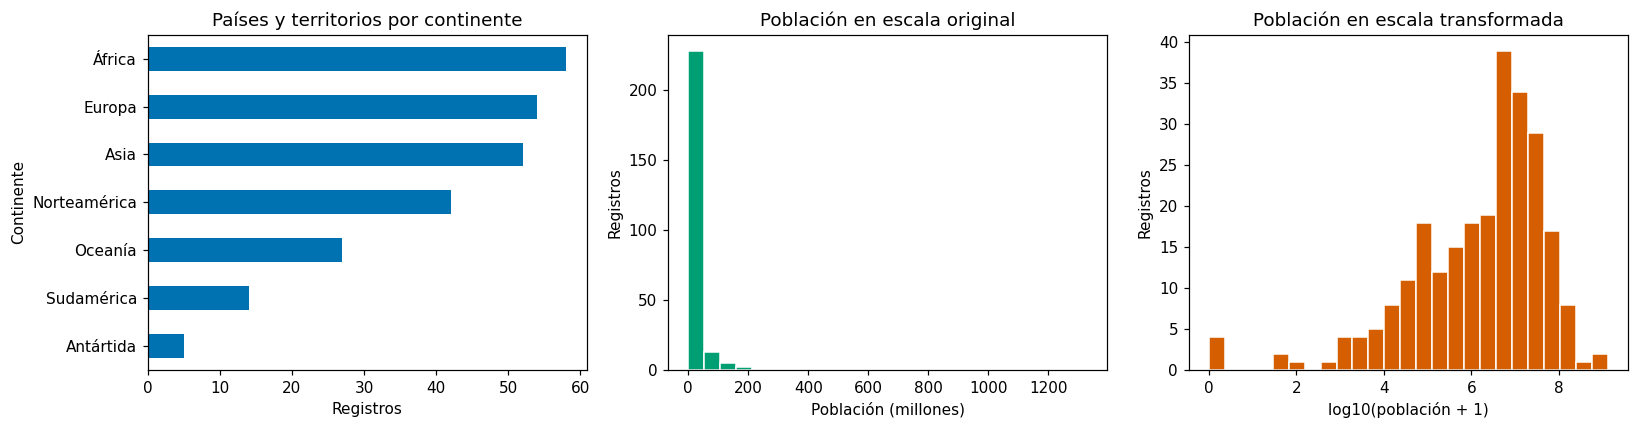

In [8]:
q1, q3 = geografia['population'].quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
es_extremo = ~geografia['population'].between(limite_inferior, limite_superior)
print(f'Candidatos extremos de población por IQR: {int(es_extremo.sum())}')
display(geografia.loc[es_extremo, ['name', 'population']].sort_values('population', ascending=False).head(10))

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
frecuencia_continente['frecuencia'].sort_values().plot.barh(ax=ejes[0], color='#0072B2')
ejes[0].set(title='Países y territorios por continente', xlabel='Registros', ylabel='Continente')
ejes[1].hist(geografia['poblacion_millones'], bins=25, color='#009E73', edgecolor='white')
ejes[1].set(title='Población en escala original', xlabel='Población (millones)', ylabel='Registros')
ejes[2].hist(np.log10(geografia['population'] + 1), bins=25, color='#D55E00', edgecolor='white')
ejes[2].set(title='Población en escala transformada', xlabel='log10(población + 1)', ylabel='Registros')
fig.tight_layout()
plt.show()

**Interpretación:** los registros de mayor población producen una cola larga y comprimen
la mayor parte del histograma en escala original. La transformación `log10(población + 1)`
facilita ver los valores pequeños y admite registros con población cero, pero no modifica los
datos de origen ni demuestra normalidad. Se identifican 33 candidatos extremos por IQR y se
conservan todos, pues no hay evidencia de que esas poblaciones sean errores.

## 8. Relaciones entre variables numéricas
Se calcula Pearson entre superficie y población, excluyendo identificadores. La dispersión
en escala logarítmica facilita la lectura de magnitudes muy diferentes; solo para esa gráfica
se omiten ceros, ya que el logaritmo de cero no está definido. La correlación de la tabla
se calcula en la escala original y no equivale a la relación mostrada en escala logarítmica.

,area,population
area,1.000,0.413
population,0.413,1.000


Registros incluidos en la dispersión logarítmica: 248 de 252


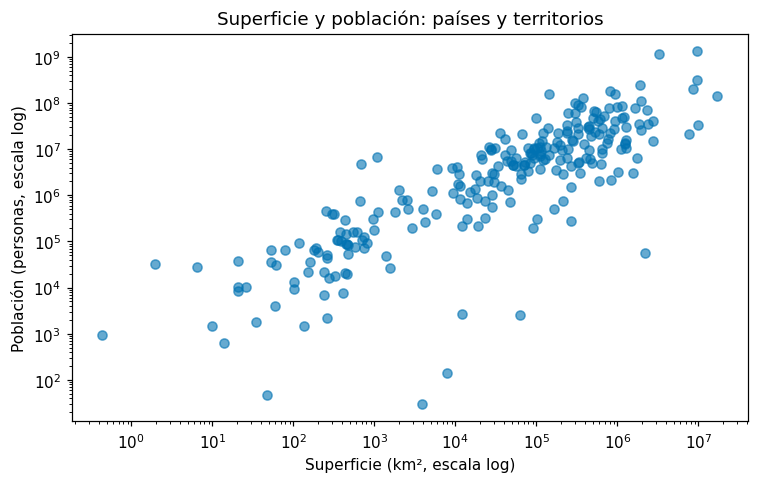

In [9]:
correlacion = geografia[['area', 'population']].corr()
display(correlacion.round(3))
validos_log = geografia.loc[(geografia['area'] > 0) & (geografia['population'] > 0)]
print(f'Registros incluidos en la dispersión logarítmica: {len(validos_log)} de {len(geografia)}')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(validos_log['area'], validos_log['population'], alpha=0.6, color='#0072B2')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set(title='Superficie y población: países y territorios', xlabel='Superficie (km², escala log)',
       ylabel='Población (personas, escala log)')
fig.tight_layout()
plt.show()

**Interpretación:** Pearson es aproximadamente **0,413**, una asociación positiva que deja
mucha variación sin describir. Tener mayor superficie no determina por sí solo una población
mayor. La presencia de valores extremos afecta Pearson; tampoco se ha demostrado linealidad,
normalidad ni homogeneidad de varianzas para una inferencia estadística. Un coeficiente no
permite deducir causalidad ni justificar eliminar una variable automáticamente.

## 9. Tabla de contingencia y asociación categórica
Como aplicación del temario, se cruza continente con densidad **por debajo de la mediana**
o **desde la mediana**. Es una clasificación relativa a esta muestra, no un estándar demográfico.
Se calculan porcentajes por fila, chi-cuadrado, coeficiente de contingencia de Pearson y V de Cramér.

Antes de interpretar chi-cuadrado se revisan las frecuencias esperadas: ninguna debe ser menor
que 1 y no más del 20 % debe ser menor que 5. Estas condiciones numéricas no reemplazan
el supuesto de observaciones independientes ni convierten el conjunto en una muestra aleatoria.

In [10]:
con_densidad = geografia.dropna(subset=['densidad_hab_km2']).copy()
mediana_densidad = con_densidad['densidad_hab_km2'].median()
con_densidad['nivel_densidad'] = np.where(
    con_densidad['densidad_hab_km2'] >= mediana_densidad, 'Desde la mediana', 'Bajo la mediana')
contingencia = pd.crosstab(con_densidad['continente'], con_densidad['nivel_densidad'])
display(contingencia)
display(contingencia.div(contingencia.sum(axis=1), axis=0).mul(100).round(2))

chi2, p_valor, grados_libertad, esperadas = chi2_contingency(contingencia)
n = contingencia.to_numpy().sum()
m = min(contingencia.shape[0] - 1, contingencia.shape[1] - 1)
v_cramer = np.sqrt(chi2 / (n * m))
coef_contingencia = np.sqrt(chi2 / (chi2 + n))
fraccion_menores_5 = (esperadas < 5).mean()
condicion_conteos = (esperadas >= 1).all() and fraccion_menores_5 <= 0.20
print(f'Mediana de corte: {mediana_densidad:.2f} hab/km²')
print(f'Esperada mínima: {esperadas.min():.2f}; porcentaje de celdas esperadas < 5: {fraccion_menores_5:.2%}')
print(f'Condiciones numéricas de frecuencias esperadas: {condicion_conteos}')
print(f'Chi-cuadrado: {chi2:.3f}; gl: {grados_libertad}; p calculado: {p_valor:.3g}')
print(f'V de Cramér: {v_cramer:.3f}; coeficiente de contingencia: {coef_contingencia:.3f}')

nivel_densidad,Bajo la mediana,Desde la mediana
continente,,
Antártida,5,0
Asia,22,30
Europa,17,37
Norteamérica,12,30
Oceanía,15,11
Sudamérica,14,0
África,40,18


nivel_densidad,Bajo la mediana,Desde la mediana
continente,,
Antártida,100.00,0.00
Asia,42.31,57.69
Europa,31.48,68.52
Norteamérica,28.57,71.43
Oceanía,57.69,42.31
Sudamérica,100.00,0.00
África,68.97,31.03


Mediana de corte: 78.09 hab/km²
Esperada mínima: 2.49; porcentaje de celdas esperadas < 5: 14.29%
Condiciones numéricas de frecuencias esperadas: True
Chi-cuadrado: 44.309; gl: 6; p calculado: 6.42e-08
V de Cramér: 0.420; coeficiente de contingencia: 0.387


**Interpretación y alcance:** la V de Cramér es aproximadamente **0,420**, lo que indica
asociación descriptiva entre continente y la clasificación de densidad utilizada. Las
condiciones numéricas de las frecuencias esperadas se cumplen: mínimo ≈ 2,49 y 14,29 % de
celdas por debajo de 5. El valor p calculado es pequeño, pero estos registros no proceden de
un muestreo aleatorio documentado y pueden tener dependencias geográficas. Por ello se muestra
como ejercicio de cálculo; **no se usa como prueba de generalización poblacional ni causalidad**.
No se interpreta el coeficiente Phi porque la tabla no es 2 × 2.

## 10. Serie histórica: Colombia y Argentina
Se filtran ambos países y se alinean por **año** con `pivot`. No se emparejan filas por su posición,
pues un orden distinto o un año ausente produciría comparaciones equivocadas.
Las cifras pertenecen a la serie histórica y no se sustituyen por las del CSV geográfico.

In [11]:
seleccion = poblacion.loc[poblacion['country'].isin(['Colombia', 'Argentina'])].copy()
comparacion = seleccion.pivot(index='year', columns='country', values='population').sort_index()
comparacion = comparacion[['Colombia', 'Argentina']]
assert comparacion.shape == (12, 2)
assert not comparacion.isna().any().any(), 'Falta un país en algún año: revisar antes de comparar'
display(comparacion)
display(comparacion.describe().round(2))

crecimiento_intervalo = comparacion.pct_change(fill_method=None).mul(100)
print('Variación porcentual respecto a la observación anterior (intervalos de 5 años):')
display(crecimiento_intervalo.round(2))

primer_anio, ultimo_anio = int(comparacion.index.min()), int(comparacion.index.max())
anios_transcurridos = ultimo_anio - primer_anio
resumen_crecimiento = pd.DataFrame({
    'poblacion_inicial': comparacion.iloc[0],
    'poblacion_final': comparacion.iloc[-1],
    'incremento_personas': comparacion.iloc[-1] - comparacion.iloc[0],
    'crecimiento_total_pct': (comparacion.iloc[-1] / comparacion.iloc[0] - 1) * 100,
    'tasa_anual_compuesta_pct': ((comparacion.iloc[-1] / comparacion.iloc[0]) ** (1 / anios_transcurridos) - 1) * 100,
})
display(resumen_crecimiento.round(2))
print('Primer año observado con población de Colombia mayor que Argentina:',
      comparacion.index[comparacion['Colombia'] > comparacion['Argentina']].min())

country,Colombia,Argentina
year,,
1952,12350771,17876956
1957,14485993,19610538
1962,17009885,21283783
1967,19764027,22934225
1972,22542890,24779799
1977,25094412,26983828
1982,27764644,29341374
1987,30964245,31620918
1992,34202721,33958947


country,Colombia,Argentina
count,12.00,12.00
mean,27256099.58,28602239.92
std,10535047.08,7546608.99
min,12350771.00,17876956.00
25%,19075491.50,22521614.50
50%,26429528.00,28162601.00
75%,35066498.25,34520076.00
max,44227550.00,40301927.00


Variación porcentual respecto a la observación anterior (intervalos de 5 años):


country,Colombia,Argentina
year,,
1952,NaN,NaN
1957,17.29,9.70
1962,17.42,8.53
1967,16.19,7.75
1972,14.06,8.05
1977,11.32,8.89
1982,10.64,8.74
1987,11.52,7.77
1992,10.46,7.39


,poblacion_inicial,poblacion_final,incremento_personas,crecimiento_total_pct,tasa_anual_compuesta_pct
country,,,,,
Colombia,12350771,44227550,31876779,258.10,2.35
Argentina,17876956,40301927,22424971,125.44,1.49


Primer año observado con población de Colombia mayor que Argentina: 1992


**Interpretación:** Colombia pasa de **12.350.771** habitantes en 1952 a **44.227.550** en
2007: un aumento de aproximadamente **258,10 %**, equivalente a una tasa anual compuesta de
**2,35 %**. Argentina pasa de **17.876.956** a **40.301.927**: aproximadamente **125,44 %**,
con tasa anual compuesta de **1,49 %**.

En **1992** Colombia supera a Argentina por primera vez entre los años observados; con estos
datos quinquenales no se identifica el año exacto del cruce. El primer valor de `pct_change`
es nulo porque no existe observación previa: es un resultado esperado, no un faltante que deba
rellenarse con cero. Esas variaciones son quinquenales y no tasas anuales.

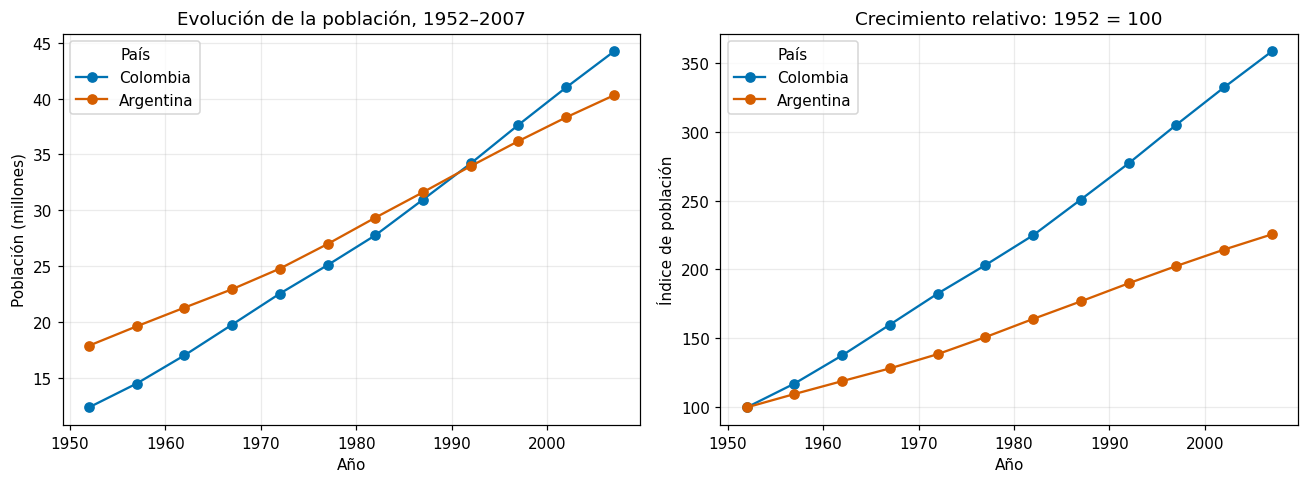

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
(comparacion / 1_000_000).plot(ax=ejes[0], marker='o', color=['#0072B2', '#D55E00'])
ejes[0].set(title='Evolución de la población, 1952–2007', xlabel='Año', ylabel='Población (millones)')

indice_base_100 = comparacion.div(comparacion.iloc[0]).mul(100)
indice_base_100.plot(ax=ejes[1], marker='o', color=['#0072B2', '#D55E00'])
ejes[1].set(title='Crecimiento relativo: 1952 = 100', xlabel='Año', ylabel='Índice de población')
for ax in ejes:
    ax.grid(alpha=0.25)
    ax.legend(title='País')
fig.tight_layout()
plt.show()

**Lectura de las gráficas:** la izquierda compara tamaños de población; la derecha elimina
la diferencia inicial de escala mediante una base común de 100. Colombia muestra mayor
crecimiento relativo durante el periodo. Los segmentos entre puntos ayudan a visualizar
la trayectoria; no representan mediciones anuales adicionales.

## 11. Regresión descriptiva y revisión de supuestos
El temario introduce regresión. Como demostración, se ajusta una recta a la población colombiana
frente al tiempo. El predictor se centra en 1952 para interpretar la pendiente en millones de
habitantes por año. Se examinan residuos para no dar por sentado que una recta describe todo el proceso.

Este ajuste resume datos observados. No se utiliza para pronosticar, hacer pruebas de hipótesis ni
explicar causas: las series temporales pueden tener autocorrelación y una tendencia curva.

Ajuste: población (millones) = 11.217 + 0.583 × (año − 1952)
R² descriptivo dentro de la muestra: 0.996


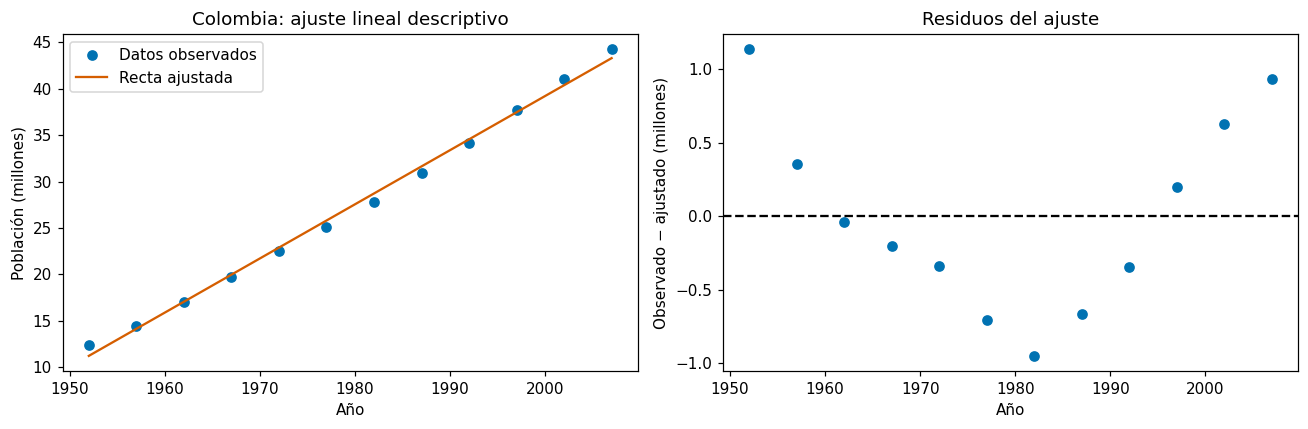

In [13]:
x = comparacion.index.to_numpy() - primer_anio
y = comparacion['Colombia'].to_numpy() / 1_000_000
pendiente, intercepto = np.polyfit(x, y, deg=1)
ajuste = pendiente * x + intercepto
residuos = y - ajuste
r2 = 1 - np.sum(residuos ** 2) / np.sum((y - y.mean()) ** 2)
print(f'Ajuste: población (millones) = {intercepto:.3f} + {pendiente:.3f} × (año − {primer_anio})')
print(f'R² descriptivo dentro de la muestra: {r2:.3f}')

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(comparacion.index, y, 'o', label='Datos observados', color='#0072B2')
ejes[0].plot(comparacion.index, ajuste, label='Recta ajustada', color='#D55E00')
ejes[0].set(title='Colombia: ajuste lineal descriptivo', xlabel='Año', ylabel='Población (millones)')
ejes[0].legend()
ejes[1].scatter(comparacion.index, residuos, color='#0072B2')
ejes[1].axhline(0, color='black', linestyle='--')
ejes[1].set(title='Residuos del ajuste', xlabel='Año', ylabel='Observado − ajustado (millones)')
fig.tight_layout()
plt.show()

**Interpretación:** un R² alto dentro de la muestra no garantiza un pronóstico fiable.
Los residuos muestran una estructura curva, por lo que una recta no captura completamente
la trayectoria. La normalidad, la homoscedasticidad y la independencia de errores no se
consideran demostradas mediante este gráfico. La pendiente absoluta tampoco es una tasa
porcentual anual: esta última se calculó por separado mediante crecimiento compuesto.

## 12. Conclusiones

1. Se cargaron los **dos CSV del ejemplo del PDF**, se identificaron sus claves y se conservaron
   intactas las tablas originales. Leer los códigos como texto evitó perder `NA` y ceros iniciales.
2. Las tablas contienen 252 registros geográficos y 1.704 históricos. No se detectaron duplicados
   ni claves repetidas. Se documentaron los faltantes existentes y una densidad no calculable;
   no se inventaron datos para completar la tabla.
3. La distribución de población es muy asimétrica. Los 33 candidatos extremos por IQR se
   conservaron porque no se comprobó que fueran errores. Las medianas y la escala transformada
   complementaron los promedios y las gráficas en escala original.
4. La relación lineal superficie–población es positiva (r ≈ 0,413), pero no determina la población
   de un territorio. La asociación continente–nivel de densidad también es descriptiva y depende
   del umbral elegido (V de Cramér ≈ 0,420).
5. De 1952 a 2007 Colombia creció aproximadamente 258,10 % y Argentina 125,44 %. En los años
   observados, Colombia supera a Argentina desde 1992. Las tasas anuales compuestas son
   aproximadamente 2,35 % y 1,49 %, respectivamente.
6. **Limitaciones:** la tabla geográfica carece de fecha de referencia por registro; los países y
   territorios no constituyen una muestra aleatoria documentada; la serie termina en 2007 y no
   registra los años intermedios. No se pueden presentar los resultados como actuales, inferir
   causalidad ni mezclar las dos poblaciones como si fueran contemporáneas.

## Correspondencia con la actividad

| Requisito de entrega | Desarrollo |
| --- | --- |
| Código Python y Pandas | Series, DataFrames, lectura de dos CSV |
| Manipulación | Tipos, filtros, columnas derivadas, índices y `pivot` |
| Limpieza de datos | Diagnóstico de nulos, códigos `NA`, duplicados y claves |
| Estadística descriptiva | `describe`, frecuencias, porcentajes y acumulados |
| Análisis de variables | Contingencia, correlación, crecimiento y ajuste descriptivo |
| Visualizaciones | Barras, histogramas, dispersión, series temporales y residuos |
| Explicaciones | Markdown y comentarios: qué se hace, por qué y qué se obtiene |

**Antes de entregar:** completar nombre, asignatura, grupo y fecha; leer las interpretaciones
y ejecutar todas las celdas en orden en Colab o Jupyter. Guardar las salidas y subir este archivo
en formato `.ipynb`. Las copias de los datos están incluidas y no requieren archivos adjuntos.